# Power Curve Analysis — ALTA10 project adaptation

**Adapted from your teammate’s `power_curve (1).ipynb`.** The same core comparisons are retained: per-turbine real power versus theoretical power and the farm fleet, grouped by month and density-corrected wind-speed bin.

**Changed for this project:** use `data/processed/scada_data.parquet`, `data/processed/metmasts_data.parquet`, and the supplied `data/raw/GE_2_85MW_103mRD_PC.csv`, detect the project root, normalize GE/WTG identifiers, handle differing power-field names, fix incomplete plotting cells, and save outputs in a separate folder.

**Interpretation:** these plots are *power-performance consistency checks*, not calibration or proof of a broken anemometer. The SCADA wind-speed field may be derived/adjusted using turbine power. This notebook does **not** apply wake, status, or curtailment filters.

## 1. Imports and project settings

In [13]:
from pathlib import Path
import math
import re
import warnings
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    def display(table):
        print(table.to_string(index=False) if hasattr(table, "to_string") else table)

# Normally no edits are needed if you save this notebook in notebooks/alex_notebooks/.
PROJECT_ROOT_OVERRIDE = None  # e.g. Path(r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project")
FALLBACK_PROJECT_ROOT = Path(r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project")

# Keep the teammate's original correction as a *provisional* assumption.
CORRECTION_STANDARD_DENSITY = 1.050817  # kg/m^3; teammate's selected value, not OEM verified
REFERENCE_DENSITY = 1.02               # kg/m^3; supplied GE reference sheet

# Main analysis choices. These are research settings, not manufacturer fault thresholds.
BIN_CUTIN_MS = 3.0
BIN_MAX_MS = 15.0
BIN_WIDTH_MS = 0.5
MIN_RECORDS_PER_BIN = 10  # teammate originally used 1; now avoid very sparse bins
MIN_BASELINE_POWER_KW = 100.0  # protect ratios from near-zero denominators
EXCLUDE_TARGET_FROM_FLEET = True  # makes fleet reference independent of target turbine

TURBINE_OF_INTEREST = "WTG172"
MONTH_OF_INTEREST = "2026-07"
OTHER_TURBINE = "WTG172"
LIDAR_EQUIPPED_TURBINES = ["WTG159", "WTG170", "WTG171", "WTG173", "WTG180", "WTG184"]

# Power units are assumed to be kW, consistent with 06_ and the GE reference CSV.
SCADA_POWER_UNITS = "kW"

## 2. Locate and load your datasets

The source of each column is printed, including whether a SCADA theoretical-power KPI exists. We **do not** quietly rename the manufacturer estimate as a measured SCADA KPI.

In [14]:
def locate_project_root():
    if PROJECT_ROOT_OVERRIDE is not None:
        chosen = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
        if not (chosen / "data").is_dir():
            raise FileNotFoundError(f"No data/ folder under override: {chosen}")
        return chosen

    candidates = []
    if "CU_CAPSTONE_PROJECT" in os.environ:
        candidates.append(Path(os.environ["CU_CAPSTONE_PROJECT"]))
    candidates += [Path.cwd(), FALLBACK_PROJECT_ROOT]
    if "__file__" in globals():
        candidates.insert(0, Path(__file__).resolve().parent)

    seen = set()
    for candidate in candidates:
        for root in (candidate, *candidate.parents):
            if str(root) in seen:
                continue
            seen.add(str(root))
            if any((root / p).is_file() for p in [
                "data/processed/scada_data.parquet",
                "data/cleaned/scada_data.parquet",
            ]):
                return root
    raise FileNotFoundError(
        "Could not find scada_data.parquet. Put this notebook in "
        "CU-Capstone-Project/notebooks/alex_notebooks/ or set PROJECT_ROOT_OVERRIDE."
    )


def first_existing(root, candidates, name, required=True):
    for relative in candidates:
        candidate = root / relative
        if candidate.is_file():
            return candidate
    if required:
        raise FileNotFoundError(
            f"Missing {name}; checked:\n" +
            "\n".join(str(root / p) for p in candidates)
        )
    return None


def normalize_turbine(value):
    if pd.isna(value):
        return pd.NA
    text = str(value).strip().upper()
    found = re.fullmatch(r"(?:(?:WTG[_\s-]*T?|GE)[_\s-]*)?(\d+)(?:\.0)?", text)
    if not found:
        raise ValueError(f"Unknown turbine ID: {value!r}")
    return "WTG" + str(int(found.group(1)))


def prefer_column(df, candidates, meaning, required=True):
    for key in candidates:
        if key in df.columns:
            return key
    if required:
        raise KeyError(f"No {meaning}. Looked for: {candidates}; found: {list(df.columns)}")
    return None


PROJECT_ROOT = locate_project_root()
DATA = PROJECT_ROOT / "data"
OUTPUT_DIR = DATA / "processed" / "partner_power_curve_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

scada_path = first_existing(PROJECT_ROOT, [
    "data/processed/scada_data.parquet",
    "data/cleaned/scada_data.parquet",
], "SCADA")
met_path = first_existing(PROJECT_ROOT, [
    "data/processed/metmasts_data.parquet",
    "data/cleaned/metmasts_data.parquet",
], "met mast", required=False)
reference_path = first_existing(PROJECT_ROOT, [
    "data/raw/GE_2_85MW_103mRD_PC.csv",
    "data/cleaned/reference_power_curve.parquet",
    "data/processed/reference_power_curve.parquet",
], "GE power curve")

print("Project root:", PROJECT_ROOT)
print("SCADA source:", scada_path)
print("Met mast source:", met_path or "not found (not needed for this analysis)")
print("GE reference source:", reference_path)
print("Output folder:", OUTPUT_DIR)

scada = pd.read_parquet(scada_path).copy()
metmasts = pd.read_parquet(met_path).copy() if met_path else pd.DataFrame()
reference_raw = (
    pd.read_csv(reference_path)
    if reference_path.suffix.lower() == ".csv"
    else pd.read_parquet(reference_path)
)

# Standardize SCADA fields without making up missing instrument measurements.
if "turbine" not in scada.columns and "turbine" in scada.index.names:
    scada = scada.reset_index()
if "turbine" not in scada.columns:
    raise KeyError("SCADA table needs a turbine identifier column.")
scada["turbine"] = scada["turbine"].map(normalize_turbine)

if not any(key in scada.columns for key in ["utc", "timestamp"]):
    scada = scada.reset_index()
time_col = prefer_column(scada, ["utc", "timestamp"], "time field")
scada["utc"] = pd.to_datetime(scada[time_col], errors="coerce", utc=True).dt.tz_localize(None)

ws_col = prefer_column(scada, ["wind_speed", "KPI_wind_speed"], "SCADA wind speed")
power_col = prefer_column(scada, ["KPI_real_power_ac", "real_power_ac"], "actual turbine electrical power")
theory_col = prefer_column(scada, ["KPI_theoretical_power", "theoretical_power"], "SCADA theoretical power", required=False)

scada["wind_speed"] = pd.to_numeric(scada[ws_col], errors="coerce")
scada["KPI_real_power_ac"] = pd.to_numeric(scada[power_col], errors="coerce")
scada["air_density"] = pd.to_numeric(scada[prefer_column(scada, ["air_density", "KPI_air_density"], "air density")], errors="coerce")
if scada["utc"].isna().any():
    print("Invalid timestamp rows excluded:", int(scada["utc"].isna().sum()))
    scada = scada.dropna(subset=["utc"])

if SCADA_POWER_UNITS != "kW":
    raise ValueError("This notebook is written for kW. Verify units before converting.")
q99 = scada["KPI_real_power_ac"].quantile(0.99)
if pd.notna(q99) and (q99 < 50 or q99 > 20000):
    warnings.warn(f"Power 99th percentile={q99:.2f}; verify that '{power_col}' is in kW.")

# Standardize the two possible GE reference file schemas.
rename_reference = {
    "WINDSPEED": "wind_speed_ref",
    "POWER_KW": "power_ref",
    "AIR_DENSITY": "air_density_ref",
    "TI_CLASS": "ti_class",
    "MODEL": "model",
}
reference = reference_raw.rename(columns=rename_reference).copy()
for name in ["wind_speed_ref", "power_ref", "air_density_ref"]:
    if name not in reference.columns:
        raise KeyError(f"Missing GE reference '{name}'. Available: {list(reference.columns)}")
    reference[name] = pd.to_numeric(reference[name], errors="coerce")
if "ti_class" not in reference.columns:
    raise KeyError("Reference curve missing TI_CLASS/ti_class; cannot select normal TI reliably.")
reference["ti_class"] = reference["ti_class"].astype(str).str.strip().str.lower()
reference = reference.dropna(subset=["wind_speed_ref", "power_ref", "air_density_ref"])
reference = reference.sort_values(["air_density_ref", "wind_speed_ref"]).reset_index(drop=True)

print(f"SCADA rows: {len(scada):,}; turbines: {scada.turbine.nunique()}")
print(f"Met mast rows: {len(metmasts):,}")
print(f"GE reference rows: {len(reference):,}")
print("SCADA wind speed column:", ws_col)
print("Actual electrical power column:", power_col)
print("SCADA theoretical power column:", theory_col or "not provided")
print("NOTE: SCADA wind speed may be power-adjusted or power-derived; manufacturer agreement is not calibration.")

Project root: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project
SCADA source: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\scada_data.parquet
Met mast source: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\metmasts_data.parquet
GE reference source: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\raw\GE_2_85MW_103mRD_PC.csv
Output folder: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\partner_power_curve_analysis
SCADA rows: 1,833,846; turbines: 47
Met mast rows: 39,306
GE reference rows: 495
SCADA wind speed column: wind_speed
Actual electrical power column: KPI_real_power_ac
SCADA theoretical power column: KPI_theoretical_power
NOTE: SCADA wind speed may be power-adjusted or power-derived; manufacturer agreement is not calibration.


### Create list of all turbines

In [15]:
turbines = sorted(scada["turbine"].dropna().unique())
print(f"{len(turbines)} turbines:", ", ".join(turbines))
print("SCADA date range:", scada.utc.min(), "through", scada.utc.max())
print("Observed source columns:", {"wind_speed": ws_col, "actual_power": power_col,
                                   "theoretical_KPI": theory_col or "not available"})

47 turbines: WTG150, WTG151, WTG152, WTG153, WTG154, WTG155, WTG156, WTG157, WTG158, WTG159, WTG161, WTG162, WTG163, WTG164, WTG165, WTG166, WTG167, WTG168, WTG169, WTG170, WTG171, WTG172, WTG173, WTG174, WTG175, WTG176, WTG177, WTG178, WTG179, WTG180, WTG181, WTG182, WTG183, WTG184, WTG185, WTG186, WTG187, WTG188, WTG189, WTG190, WTG191, WTG192, WTG193, WTG194, WTG195, WTG196, WTG197
SCADA date range: 2026-01-01 08:00:00 through 2026-09-29 06:50:00
Observed source columns: {'wind_speed': 'wind_speed', 'actual_power': 'KPI_real_power_ac', 'theoretical_KPI': 'KPI_theoretical_power'}


## 3. Correct wind speeds and identify the theoretical-power source

The correction function below is **your partner’s original empirical formula**, retained for comparability. The selected density standard is a provisional assumption. If the processed SCADA table lacks `KPI_theoretical_power`, the notebook instead calculates a clearly labeled **GE manufacturer curve estimate**, and records that different provenance.

In [16]:
# Unchanged formula from the teammate's notebook.
def corrected_wind_speed(wind_speed, air_density, ws0=7, ws1=12,
                         ex0=1/3, ex1=2/3, standard=1.225):
    frac = np.clip((wind_speed - ws0) / (ws1 - ws0), 0, 1)
    exponent = ex0 + frac * (ex1 - ex0)
    return wind_speed * (air_density / standard) ** exponent

scada["air_density"] = scada["air_density"].where(scada["air_density"].gt(0))
reference["air_density_ref"] = reference["air_density_ref"].where(reference["air_density_ref"].gt(0))
scada["corrected_ws"] = corrected_wind_speed(
    scada["wind_speed"], scada["air_density"], standard=CORRECTION_STANDARD_DENSITY
)
reference["corrected_ref_ws"] = corrected_wind_speed(
    reference["wind_speed_ref"], reference["air_density_ref"], standard=CORRECTION_STANDARD_DENSITY
)

normal = reference[reference.ti_class.eq("normal")].copy()
if normal.empty:
    raise ValueError("No normal TI GE reference rows found.")
nearest_density = float(
    normal.air_density_ref.dropna().unique()[
        np.argmin(np.abs(normal.air_density_ref.dropna().unique() - REFERENCE_DENSITY))
    ]
)
reference_standard = (
    normal[np.isclose(normal.air_density_ref, nearest_density)]
    .groupby("corrected_ref_ws", as_index=False)["power_ref"].mean()
    .sort_values("corrected_ref_ws")
)
if len(reference_standard) < 2:
    raise ValueError("Manufacturer reference has fewer than two valid points.")

# Important: do not silently call this GE-derived estimate a SCADA KPI.
if theory_col is not None:
    scada["comparison_theoretical_power"] = pd.to_numeric(scada[theory_col], errors="coerce")
    THEORETICAL_SOURCE = f"SCADA field: {theory_col}"
    THEORETICAL_PLOT_LABEL = "SCADA theoretical power"
else:
    scada["comparison_theoretical_power"] = np.interp(
        scada["corrected_ws"].to_numpy(dtype=float),
        reference_standard.corrected_ref_ws.to_numpy(dtype=float),
        reference_standard.power_ref.to_numpy(dtype=float),
        left=np.nan, right=np.nan
    )
    THEORETICAL_SOURCE = (
        f"Estimated from GE normal-TI power curve at density {nearest_density:g} kg/m³ "
        f"(NOT a SCADA theoretical KPI)"
    )
    THEORETICAL_PLOT_LABEL = "GE reference estimate"

print("Theoretical power source:", THEORETICAL_SOURCE)
print("Reference curve chosen for GE estimate:", nearest_density, "kg/m³")
print("Valid SCADA corrected speeds:", scada.corrected_ws.notna().sum())
print("Valid theoretical/GE estimates:", scada.comparison_theoretical_power.notna().sum())

Theoretical power source: SCADA field: KPI_theoretical_power
Reference curve chosen for GE estimate: 1.02 kg/m³
Valid SCADA corrected speeds: 1684856
Valid theoretical/GE estimates: 1833166


## 4. Generate monthly, binned power curves

Keep the teammate’s main comparisons: mean actual, mean theoretical, and mean fleet power in each wind-speed bin, plus relative differences. For more defensible fleet comparisons the default is **leave-one-turbine-out** and a 10-observation minimum per plotted bin. These are explicit differences from the original code; they do not establish true sensor bias.

In [17]:
def prepare_curve_bins(df, p="M", cutin=BIN_CUTIN_MS, rated=BIN_MAX_MS,
                       width=BIN_WIDTH_MS, wind_speed="corrected_ws"):
    if width <= 0 or rated <= cutin:
        raise ValueError("Require positive width and rated > cutin.")
    valid = df[wind_speed].between(cutin, rated) & df.utc.notna() & df.turbine.notna()
    out = df.loc[valid, [
        "utc", "turbine", "air_density", wind_speed,
        "KPI_real_power_ac", "comparison_theoretical_power"
    ]].copy()
    out["period"] = out.utc.dt.to_period(p)
    n_bins = int(np.ceil((rated - cutin) / width))
    out["bin"] = np.floor((out[wind_speed] - cutin) / width).astype(int).clip(0, n_bins - 1)
    return out


def compute_fleet_means(binned):
    power_ok = binned.loc[binned.KPI_real_power_ac.notna()]
    return power_ok.groupby(["period", "bin"], observed=True).agg(
        fleet_sum=("KPI_real_power_ac", "sum"),
        n_fleet=("KPI_real_power_ac", "size"),
        n_fleet_turbines=("turbine", "nunique")
    ).reset_index()


prepared = prepare_curve_bins(scada)
fleet_bins = compute_fleet_means(prepared)
print(f"Prepared valid wind-speed rows: {len(prepared):,}; fleet bins: {len(fleet_bins):,}")


def avg_power_curve(df_full, turbine, p="M", cutin=BIN_CUTIN_MS, rated=BIN_MAX_MS,
                    width=BIN_WIDTH_MS, wind_speed="corrected_ws",
                    min_count=MIN_RECORDS_PER_BIN, exclude_target_from_fleet=EXCLUDE_TARGET_FROM_FLEET,
                    fleet_reference=None):
    """Monthly bin means, consistent with teammate's method.

    Binned input avoids recomputing the full farm for every turbine.
    Relative differences are equal-weighted across *valid bins*, not records.
    """
    df_all = df_full if {"period", "bin"}.issubset(df_full.columns) else prepare_curve_bins(
        df_full, p=p, cutin=cutin, rated=rated, width=width, wind_speed=wind_speed
    )
    target = df_all.loc[df_all.turbine.eq(turbine)]
    output_cols = ["period", "bin", "mean_real_power", "mean_theoretical_power", "n",
                   "mean_air_density", "mean_fleet_power", "n_fleet", "n_fleet_turbines",
                   wind_speed, "turbine", "perc_diff_theoretical", "perc_diff_fleet",
                   "avg_perc_diff_theoretical", "avg_perc_diff_fleet",
                   "n_valid_theoretical_bins", "n_valid_fleet_bins"]
    if target.empty:
        return pd.DataFrame(columns=output_cols)

    target_bins = target.groupby(["period", "bin"], observed=True).agg(
        mean_real_power=("KPI_real_power_ac", "mean"),
        mean_theoretical_power=("comparison_theoretical_power", "mean"),
        mean_air_density=("air_density", "mean"),
        n=("KPI_real_power_ac", "count"),
        sum_target_power=("KPI_real_power_ac", "sum")
    ).reset_index()

    fleet = fleet_reference if fleet_reference is not None else compute_fleet_means(df_all)
    target_bins = target_bins.merge(fleet, on=["period", "bin"], how="left", validate="one_to_one")

    if exclude_target_from_fleet:
        # Do not compare the turbine with a fleet reference that includes its own output.
        sum_reference = target_bins.fleet_sum - target_bins.sum_target_power
        count_reference = target_bins.n_fleet - target_bins.n
        target_bins["n_fleet_turbines"] = target_bins.n_fleet_turbines - (target_bins.n.gt(0)).astype(int)
        target_bins["n_fleet"] = count_reference
        target_bins["mean_fleet_power"] = sum_reference / count_reference.where(count_reference.gt(0))
    else:
        target_bins["mean_fleet_power"] = target_bins.fleet_sum / target_bins.n_fleet.where(target_bins.n_fleet.gt(0))

    target_bins[wind_speed] = np.minimum(
        cutin + (target_bins["bin"] + .5) * width, rated
    )
    target_bins["turbine"] = turbine

    valid_target = target_bins.n.ge(min_count) & target_bins.mean_real_power.notna()
    valid_theory = valid_target & target_bins.mean_theoretical_power.gt(MIN_BASELINE_POWER_KW)
    valid_fleet = valid_target & target_bins.mean_fleet_power.gt(MIN_BASELINE_POWER_KW)
    target_bins["perc_diff_theoretical"] = np.where(
        valid_theory,
        target_bins.mean_real_power / target_bins.mean_theoretical_power.replace(0, np.nan) - 1,
        np.nan
    )
    target_bins["perc_diff_fleet"] = np.where(
        valid_fleet,
        target_bins.mean_real_power / target_bins.mean_fleet_power.replace(0, np.nan) - 1,
        np.nan
    )
    g = target_bins.groupby("period", observed=True)
    target_bins["avg_perc_diff_theoretical"] = g.perc_diff_theoretical.transform("mean")
    target_bins["avg_perc_diff_fleet"] = g.perc_diff_fleet.transform("mean")
    target_bins["n_valid_theoretical_bins"] = g.perc_diff_theoretical.transform("count")
    target_bins["n_valid_fleet_bins"] = g.perc_diff_fleet.transform("count")
    return target_bins[output_cols].sort_values(["period", "bin"]).reset_index(drop=True)

Prepared valid wind-speed rows: 1,207,848; fleet bins: 216


### Summarize all available turbines

In [18]:
summaries = []
monthly_bins = []
for w in turbines:
    res = avg_power_curve(prepared, w, fleet_reference=fleet_bins)
    if res.empty:
        continue
    monthly_bins.append(res)
    summary = res[[
        "period", "turbine", "avg_perc_diff_theoretical", "avg_perc_diff_fleet",
        "n_valid_theoretical_bins", "n_valid_fleet_bins"
    ]].drop_duplicates(["period", "turbine"])
    summaries.append(summary)

if not summaries:
    raise ValueError("No turbine-month power curves available. Check wind speed and power fields.")

turbine_summary = pd.concat(summaries, ignore_index=True).sort_values(
    ["period", "turbine"]
).reset_index(drop=True)

all_turbine_bins = pd.concat(monthly_bins, ignore_index=True)
print("Monthly summary rows:", len(turbine_summary), "| Binned curve rows:", len(all_turbine_bins))
print("Theoretical source:", THEORETICAL_SOURCE)
display(turbine_summary.head(12))

Monthly summary rows: 409 | Binned curve rows: 9810
Theoretical source: SCADA field: KPI_theoretical_power


,period,turbine,avg_perc_diff_theoretical,avg_perc_diff_fleet,n_valid_theoretical_bins,n_valid_fleet_bins
0,2026-01,WTG150,-0.152257,-0.134332,22,22
1,2026-01,WTG151,0.169107,0.209164,22,22
2,2026-01,WTG152,0.129238,0.162971,21,21
3,2026-01,WTG153,-0.055836,-0.041195,21,21
4,2026-01,WTG154,0.119337,0.145155,22,22
5,2026-01,WTG155,-0.515891,-0.507392,20,20
6,2026-01,WTG156,0.202324,0.226595,19,19
7,2026-01,WTG157,-0.118863,-0.118675,19,19
8,2026-01,WTG158,0.083744,0.101578,19,19
9,2026-01,WTG159,-0.090648,-0.081731,20,20


### Summary statistics and missing turbine-month combinations

In [19]:
print("Summary shape:", turbine_summary.shape)
print("\nActual versus theoretical/reference difference (fraction):")
print(turbine_summary.avg_perc_diff_theoretical.describe().round(3))
print("\nActual versus other-turbine fleet difference (fraction):")
print(turbine_summary.avg_perc_diff_fleet.describe().round(3))

all_periods = sorted(scada.utc.dt.to_period("M").dropna().unique())
expected = pd.MultiIndex.from_product([all_periods, turbines], names=["period", "turbine"]).to_frame(index=False)
missing = expected.merge(
    turbine_summary[["period", "turbine"]], on=["period", "turbine"],
    how="left", indicator=True
)
missing = missing[missing._merge.eq("left_only")].drop(columns="_merge")
print(f"\nExpected turbine-month rows: {len(expected):,}")
print(f"Observed turbine-month rows: {len(turbine_summary):,}")
print(f"Missing combinations: {len(missing):,}")
if not missing.empty:
    display(missing.head(30))

Summary shape: (409, 6)

Actual versus theoretical/reference difference (fraction):
count    409.000
mean      -0.065
std        0.164
min       -0.720
25%       -0.124
50%       -0.032
75%        0.035
max        0.275
Name: avg_perc_diff_theoretical, dtype: float64

Actual versus other-turbine fleet difference (fraction):
count    409.000
mean       0.004
std        0.172
min       -0.691
25%       -0.057
50%        0.038
75%        0.120
max        0.284
Name: avg_perc_diff_fleet, dtype: float64

Expected turbine-month rows: 423
Observed turbine-month rows: 409
Missing combinations: 14


,period,turbine
65,2026-02,WTG169
112,2026-03,WTG169
159,2026-04,WTG169
173,2026-04,WTG183
206,2026-05,WTG169
220,2026-05,WTG183
253,2026-06,WTG169
267,2026-06,WTG183
300,2026-07,WTG169
314,2026-07,WTG183


## 5. Inspect a turbine of interest (WTG159 by default)

This repairs the teammate notebook’s WTG179/WTG159 mismatch and its broken `mean_density` plotting cell. The GE reference line is selected from **one nearest available density**, not by mixing density curves. The X-axes use the same corrected wind-speed convention.

In [20]:
if TURBINE_OF_INTEREST not in turbines:
    raise ValueError(f"{TURBINE_OF_INTEREST} missing from SCADA; available: {turbines}")

result = avg_power_curve(prepared, TURBINE_OF_INTEREST, fleet_reference=fleet_bins)
print("Available months:", [str(p) for p in result.period.unique()])
display(result.head(10))

Available months: ['2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06', '2026-07', '2026-08', '2026-09']


,period,bin,mean_real_power,mean_theoretical_power,n,mean_air_density,mean_fleet_power,n_fleet,n_fleet_turbines,corrected_ws,turbine,perc_diff_theoretical,perc_diff_fleet,avg_perc_diff_theoretical,avg_perc_diff_fleet,n_valid_theoretical_bins,n_valid_fleet_bins
0,2026-01,0,31.172613,0.000000,523,0.983983,16.671404,22823,46,3.25,WTG172,NaN,NaN,0.11215,0.12059,16,16
1,2026-01,1,82.253846,10.762574,340,0.984545,49.235848,17989,46,3.75,WTG172,NaN,NaN,0.11215,0.12059,16,16
2,2026-01,2,148.099732,129.195715,222,0.980843,105.267074,13500,46,4.25,WTG172,0.146321,0.406895,0.11215,0.12059,16,16
3,2026-01,3,236.155845,195.267046,138,0.956462,181.737073,10372,46,4.75,WTG172,0.209399,0.299437,0.11215,0.12059,16,16
4,2026-01,4,333.569605,286.212710,119,0.956531,274.393157,7718,46,5.25,WTG172,0.165460,0.215663,0.11215,0.12059,16,16
5,2026-01,5,423.484342,389.781058,82,0.983923,380.437296,5704,46,5.75,WTG172,0.086467,0.113151,0.11215,0.12059,16,16
6,2026-01,6,593.500375,520.829870,68,0.944979,520.328069,4117,46,6.25,WTG172,0.139528,0.140627,0.11215,0.12059,16,16
7,2026-01,7,786.502228,669.337941,59,0.941573,689.262990,3132,46,6.75,WTG172,0.175045,0.141077,0.11215,0.12059,16,16
8,2026-01,8,909.389100,828.634736,40,0.975565,884.867283,2480,46,7.25,WTG172,0.097455,0.027712,0.11215,0.12059,16,16
9,2026-01,9,1112.067312,1006.463368,36,0.952185,1062.987076,1978,46,7.75,WTG172,0.104926,0.046172,0.11215,0.12059,16,16


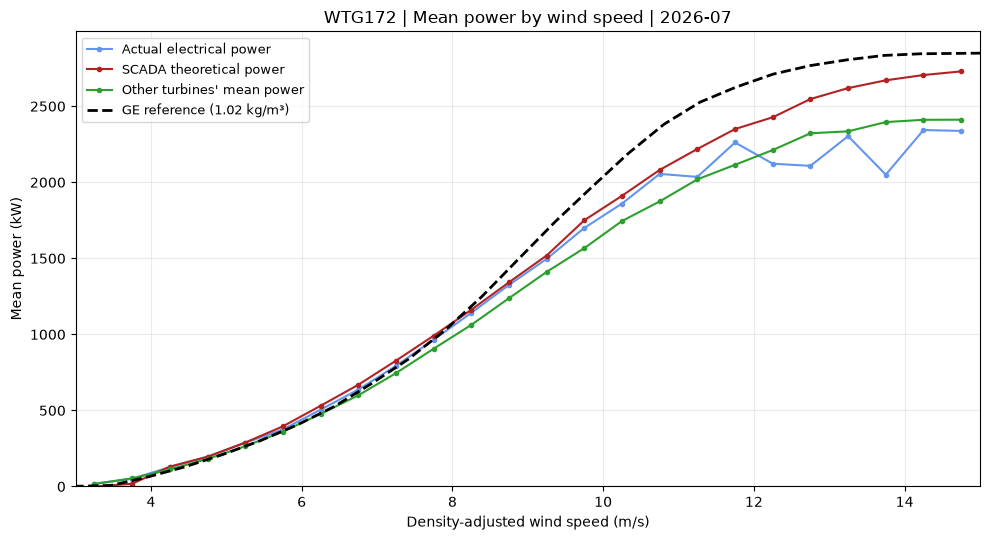

In [21]:
def show_turbine_month_curve(turbine, month_label, binned=None, plot_reference=True):
    res = avg_power_curve(prepared, turbine, fleet_reference=fleet_bins) if binned is None else binned
    available = sorted(res.period.dropna().unique())
    if not available:
        print(f"No valid curve for {turbine}.")
        return
    chosen = pd.Period(month_label, freq="M")
    if chosen not in available:
        print(f"{turbine}: requested {month_label} not present. Showing {available[-1]} instead.")
        chosen = available[-1]
    month = res.loc[res.period.eq(chosen) & res.n.ge(MIN_RECORDS_PER_BIN)].copy()
    if month.empty:
        print(f"{turbine}: no bins with at least {MIN_RECORDS_PER_BIN} observations in {chosen}.")
        return
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.plot(month.corrected_ws, month.mean_real_power, marker="o", ms=3,
            label="Actual electrical power", color="cornflowerblue")
    ax.plot(month.corrected_ws, month.mean_theoretical_power, marker="o", ms=3,
            label=THEORETICAL_PLOT_LABEL, color="firebrick")
    ax.plot(month.corrected_ws, month.mean_fleet_power, marker=".",
            label="Other turbines' mean power", color="tab:green")

    if plot_reference:
        mean_density = np.average(month.mean_air_density.fillna(REFERENCE_DENSITY), weights=month.n)
        densities = np.sort(normal.air_density_ref.dropna().unique())
        chosen_density = densities[np.argmin(abs(densities - mean_density))]
        r = normal[np.isclose(normal.air_density_ref, chosen_density)].sort_values("corrected_ref_ws")
        ax.plot(r.corrected_ref_ws, r.power_ref, "k--", linewidth=2,
                label=f"GE reference ({chosen_density:g} kg/m³)")
    ax.set_xlim(BIN_CUTIN_MS, BIN_MAX_MS)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Density-adjusted wind speed (m/s)")
    ax.set_ylabel("Mean power (kW)")
    ax.set_title(f"{turbine} | Mean power by wind speed | {chosen}")
    ax.grid(alpha=.25)
    ax.legend(fontsize=9)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{turbine}_{chosen}_power_curve.png", dpi=180, bbox_inches="tight")
    plt.show()
    return month

month_table = show_turbine_month_curve(TURBINE_OF_INTEREST, MONTH_OF_INTEREST, binned=result)

### Inspect a second turbine across all available months

This fixes the original title mismatch (the notebook analyzed WTG173 but labeled WTG157).

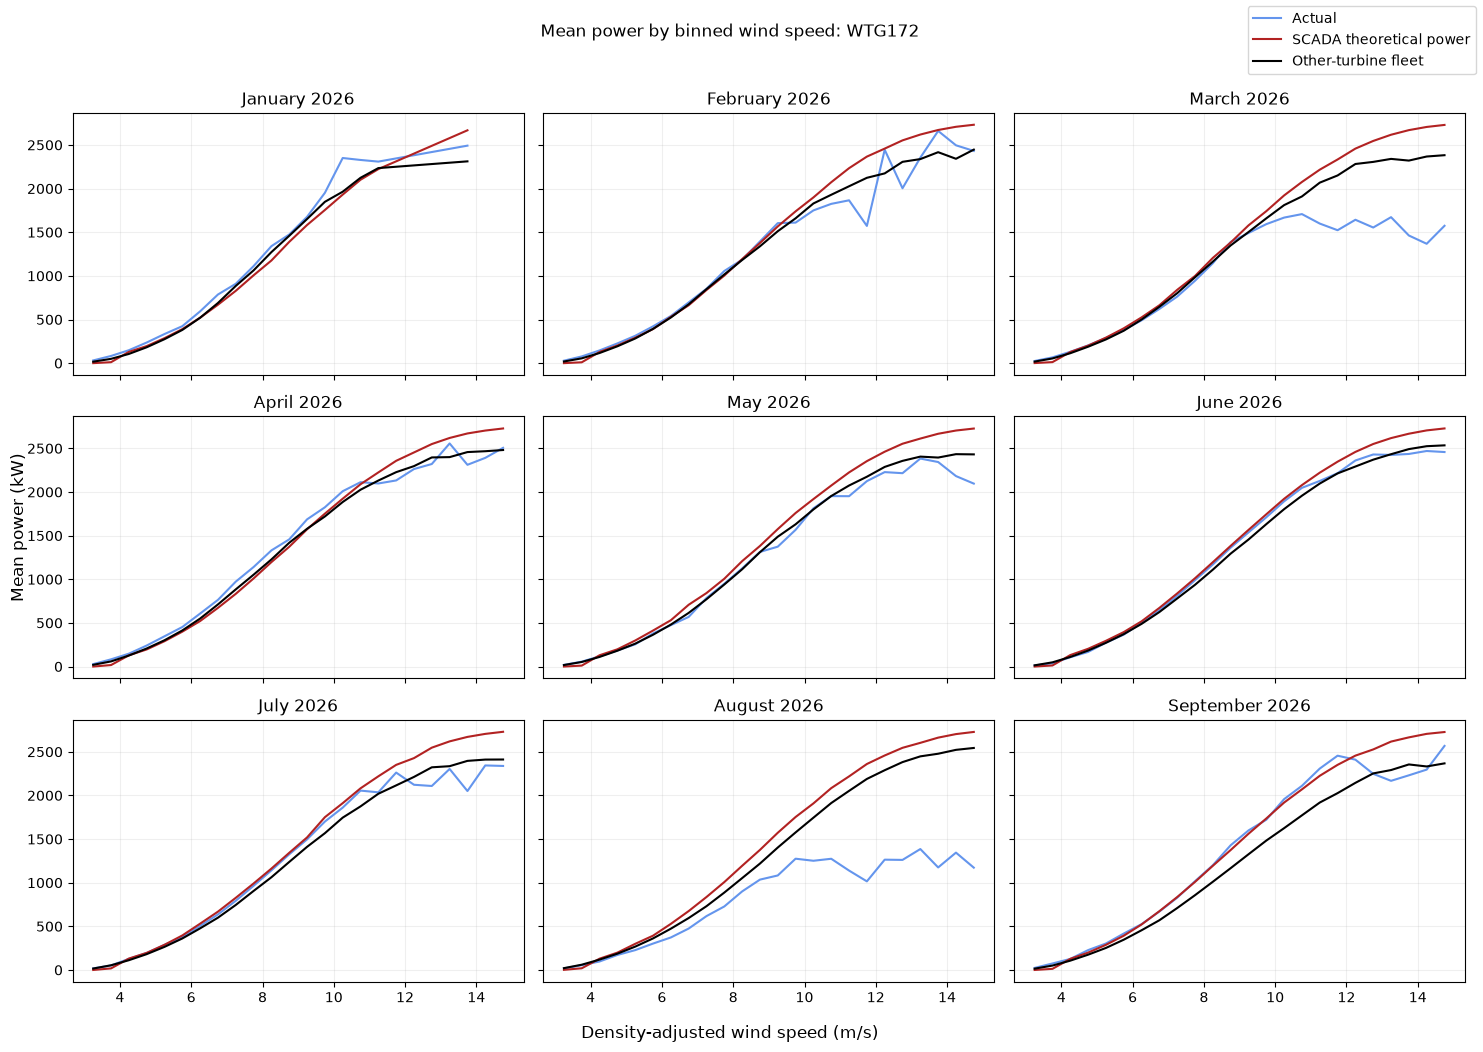

In [22]:
if OTHER_TURBINE in turbines:
    other_result = avg_power_curve(prepared, OTHER_TURBINE, fleet_reference=fleet_bins)
    available_months = sorted(other_result.period.unique())
    ncols = 3
    nrows = int(math.ceil(len(available_months) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, max(4.5, 3.5*nrows)), sharex=True, sharey=True)
    for ax, per in zip(np.ravel(axes), available_months):
        g = other_result.loc[other_result.period.eq(per) & other_result.n.ge(MIN_RECORDS_PER_BIN)]
        ax.plot(g.corrected_ws, g.mean_real_power, label="Actual", color="cornflowerblue")
        ax.plot(g.corrected_ws, g.mean_theoretical_power, label=THEORETICAL_PLOT_LABEL, color="firebrick")
        ax.plot(g.corrected_ws, g.mean_fleet_power, label="Other-turbine fleet", color="black")
        ax.set_title(per.strftime("%B %Y"))
        ax.grid(alpha=.2)
    for ax in list(np.ravel(axes))[len(available_months):]:
        ax.axis("off")
    fig.supxlabel("Density-adjusted wind speed (m/s)")
    fig.supylabel("Mean power (kW)")
    fig.suptitle(f"Mean power by binned wind speed: {OTHER_TURBINE}")
    handles, labels = np.ravel(axes)[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right")
    fig.tight_layout(rect=[0, 0, 1, .96])
    fig.savefig(OUTPUT_DIR / f"{OTHER_TURBINE}_monthly_power_curves.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print(f"{OTHER_TURBINE} is not present. Skipping its monthly plot.")

## 6. Optional: overview of the six LiDAR-equipped turbine locations

**Note:** These are still SCADA-power relationships; the six sites are merely sites where other notebooks also have LiDAR data. No LiDAR values are read here.

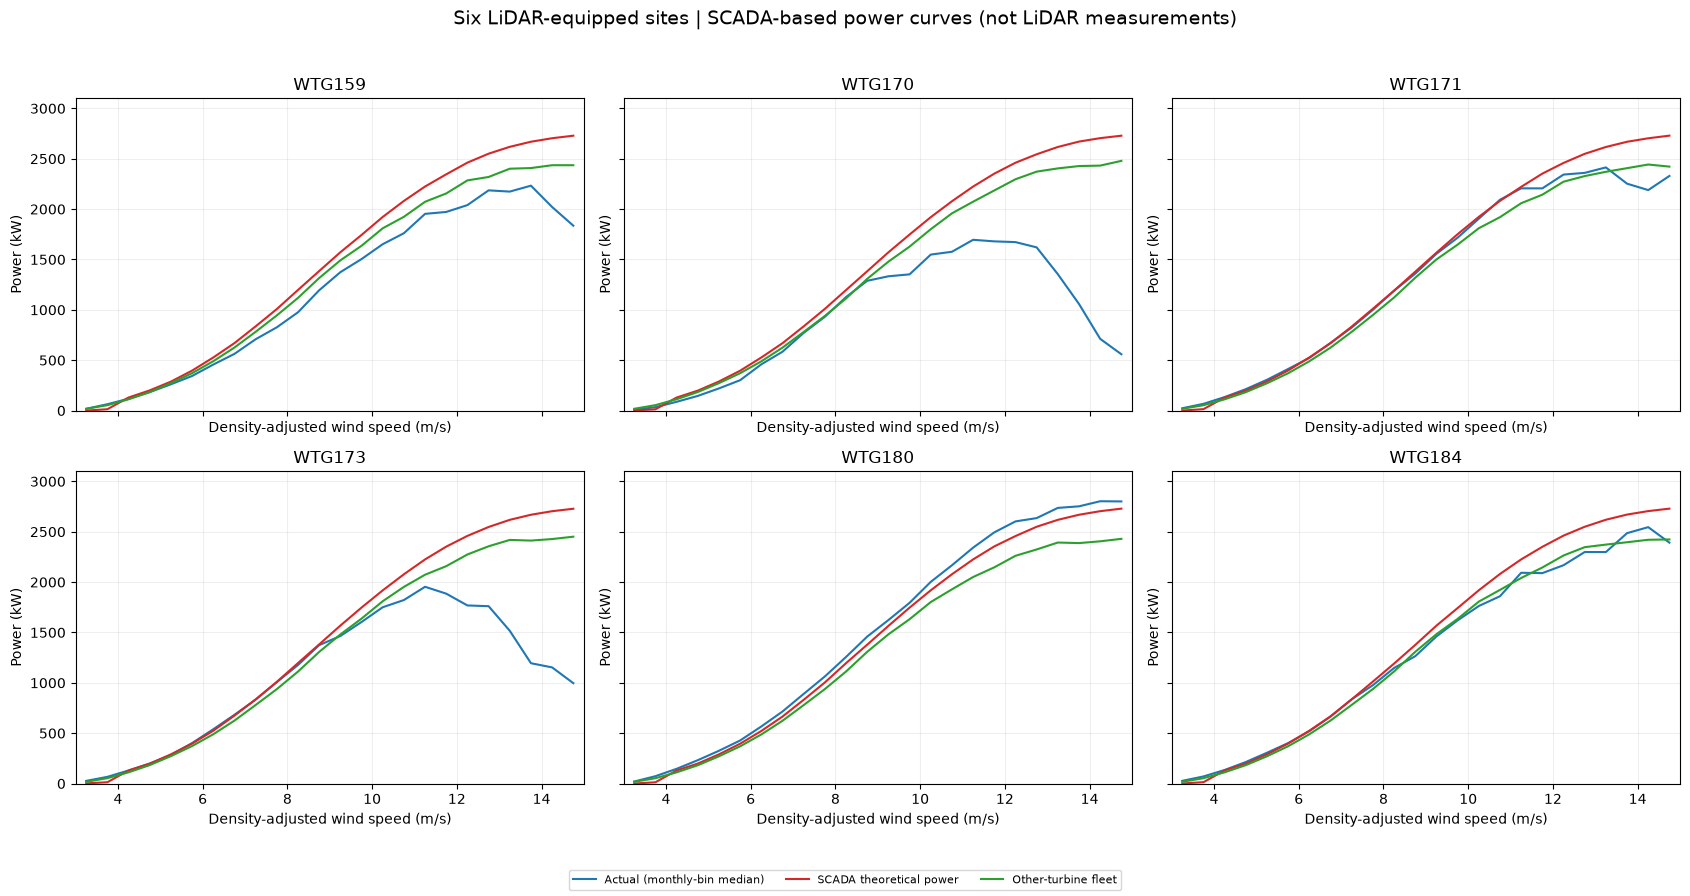

In [23]:
selected_sites = [t for t in LIDAR_EQUIPPED_TURBINES if t in turbines]
fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex=True, sharey=True)
for ax, turbine in zip(axes.flat, selected_sites):
    g = all_turbine_bins.loc[
        all_turbine_bins.turbine.eq(turbine) & all_turbine_bins.n.ge(MIN_RECORDS_PER_BIN)
    ]
    # Across all months: show monthly bin curves with light lines, then median by bin.
    if not g.empty:
        summary_curve = g.groupby("bin").agg(
            x=("corrected_ws", "mean"), real=("mean_real_power", "median"),
            theory=("mean_theoretical_power", "median"), fleet=("mean_fleet_power", "median")
        ).sort_values("x")
        ax.plot(summary_curve.x, summary_curve.real, label="Actual (monthly-bin median)", color="tab:blue")
        ax.plot(summary_curve.x, summary_curve.theory, label=THEORETICAL_PLOT_LABEL, color="tab:red")
        ax.plot(summary_curve.x, summary_curve.fleet, label="Other-turbine fleet", color="tab:green")
    ax.set(title=turbine, xlim=(BIN_CUTIN_MS, BIN_MAX_MS), ylim=(0, 3100))
    ax.grid(alpha=.2)
    ax.set_xlabel("Density-adjusted wind speed (m/s)")
    ax.set_ylabel("Power (kW)")
for ax in list(axes.flat)[len(selected_sites):]:
    ax.axis("off")
fig.suptitle("Six LiDAR-equipped sites | SCADA-based power curves (not LiDAR measurements)", fontsize=14)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8)
fig.tight_layout(rect=[0, .055, 1, .96])
fig.savefig(OUTPUT_DIR / "six_lidar_sites_scada_power_overview.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Save reproducible summary tables

In [12]:
turbine_summary.to_csv(OUTPUT_DIR / "monthly_turbine_power_summary.csv", index=False)
all_turbine_bins.to_csv(OUTPUT_DIR / "monthly_turbine_power_bins.csv", index=False)
missing.to_csv(OUTPUT_DIR / "missing_turbine_month_combinations.csv", index=False)

with open(OUTPUT_DIR / "source_and_assumptions.txt", "w", encoding="utf-8") as f:
    f.write(f"SCADA source: {scada_path}\n")
    f.write(f"Met source: {met_path} (not used in power curves)\n")
    f.write(f"GE reference: {reference_path}\n")
    f.write(f"Wind field: {ws_col}\nActual-power field: {power_col}\n")
    f.write(f"Theoretical source: {THEORETICAL_SOURCE}\n")
    f.write(f"Correction standard density: {CORRECTION_STANDARD_DENSITY} kg/m3 (teammate provisional)\n")
    f.write(f"Bin width {BIN_WIDTH_MS}; range {BIN_CUTIN_MS}-{BIN_MAX_MS}; min per bin {MIN_RECORDS_PER_BIN}\n")
    f.write(f"Fleet excludes target: {EXCLUDE_TARGET_FROM_FLEET}\n")
    f.write(f"Min power denominator: {MIN_BASELINE_POWER_KW} kW\n")
    f.write("No wake, fault, curtailment/status, or turbine-operating-state screen is used.\n")
    f.write("Observed power vs theoretical is power consistency, not calibration.\n")

print("All power-curve tables and figures saved to:", OUTPUT_DIR)
print("This analysis does not identify anemometer bias on its own.")

All power-curve tables and figures saved to: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\partner_power_curve_analysis
This analysis does not identify anemometer bias on its own.


Using 08 screening run: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\08_scada_screening\run_20261029T040948431080Z
Output folder: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\09_WTG172_power_flag_overlap
60 flagged 10-minute timestamps, 3 distinct days.
Flagged months: 2026-08, 2026-09
Event records from 08:


,reason,first_timestamp_label_utc,last_timestamp_label_utc,records
10,Sustained positive baseline departure,2026-08-10 03:00:00+00:00,2026-08-10 05:30:00+00:00,16
11,Sustained positive baseline departure,2026-08-10 06:00:00+00:00,2026-08-10 06:30:00+00:00,4
12,Sustained positive baseline departure,2026-08-10 06:50:00+00:00,2026-08-10 07:10:00+00:00,3
13,Sustained positive baseline departure,2026-08-11 02:30:00+00:00,2026-08-11 03:40:00+00:00,8
14,Sustained positive baseline departure,2026-08-11 04:40:00+00:00,2026-08-11 05:10:00+00:00,4
15,Sustained positive baseline departure,2026-09-25 02:40:00+00:00,2026-09-25 03:40:00+00:00,7
16,Sustained positive baseline departure,2026-09-25 04:00:00+00:00,2026-09-25 06:50:00+00:00,18


Comparison peers: WTG171, WTG173, WTG170
08 flagged timestamps with actual power: 60
08 flagged timestamps with theoretical/reference power: 60

Power summaries (descriptive; groups need not have identical wind distributions):


,month,screen_flag,intervals,actual_power_available,actual_power_mean_kw,theoretical_power_mean_kw,mean_actual_minus_theoretical_kw,median_actual_minus_theoretical_kw
0,2026-07,False,16,16,893.26,936.79,-43.52,-38.20
1,2026-08,False,450,450,779.07,853.36,-74.29,-47.97
2,2026-08,True,35,35,2241.93,2290.21,-48.28,-61.13
3,2026-09,False,562,562,857.54,849.25,8.29,11.87
4,2026-09,True,25,25,2144.72,1947.97,196.75,75.32


Flagged intervals with >= 10 nonflagged SAME-month/speed-bin comparators: 9
Mean event power-gap difference from matched nonflagged bins (kW): 140.73


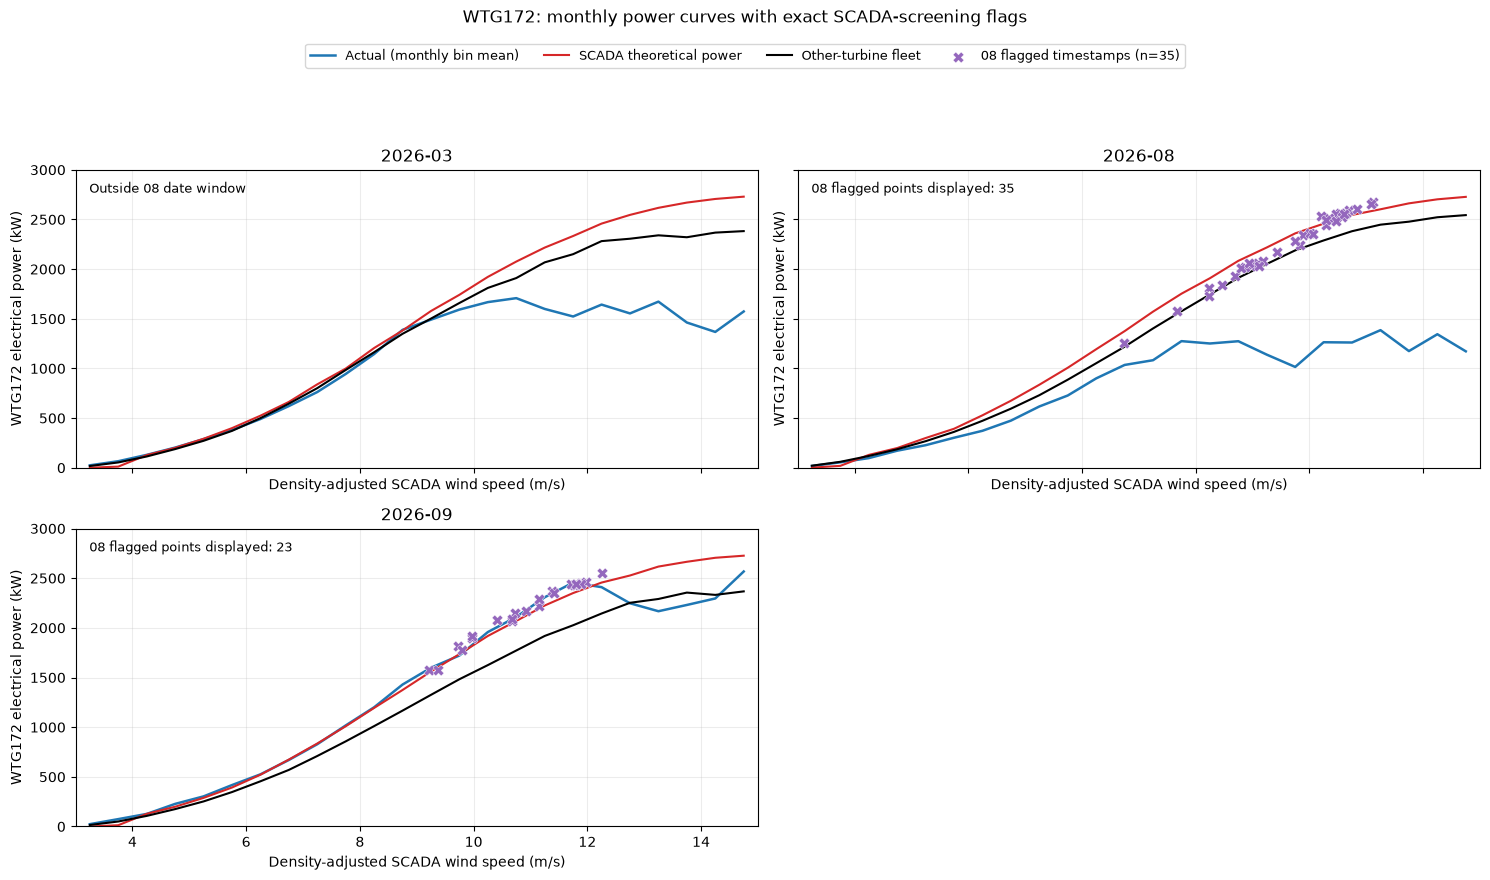

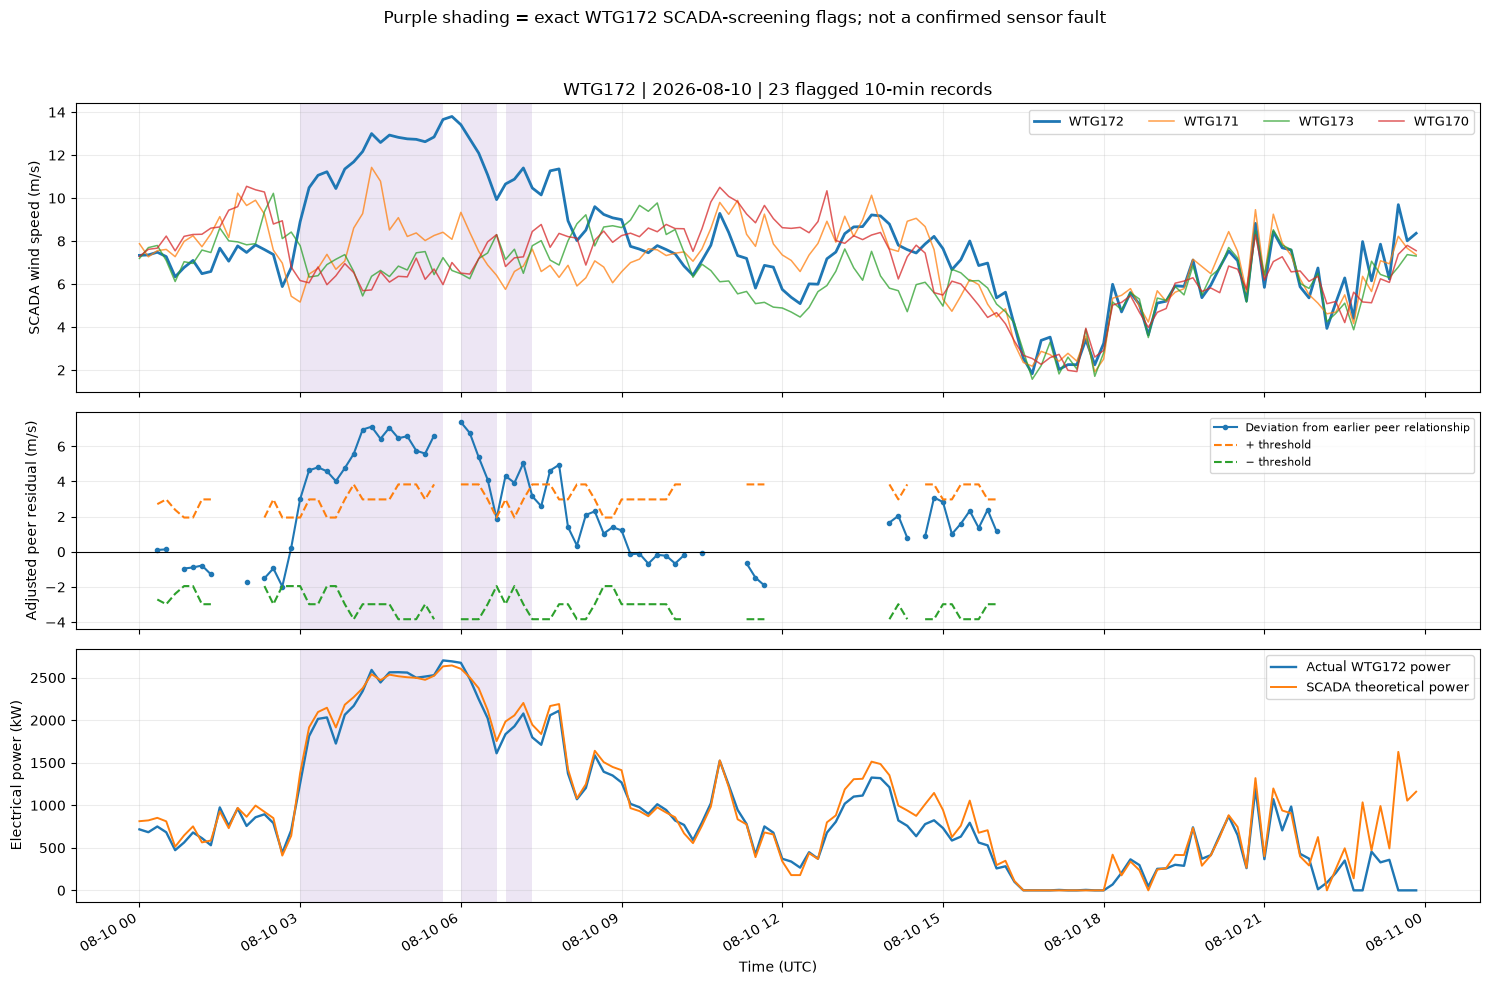

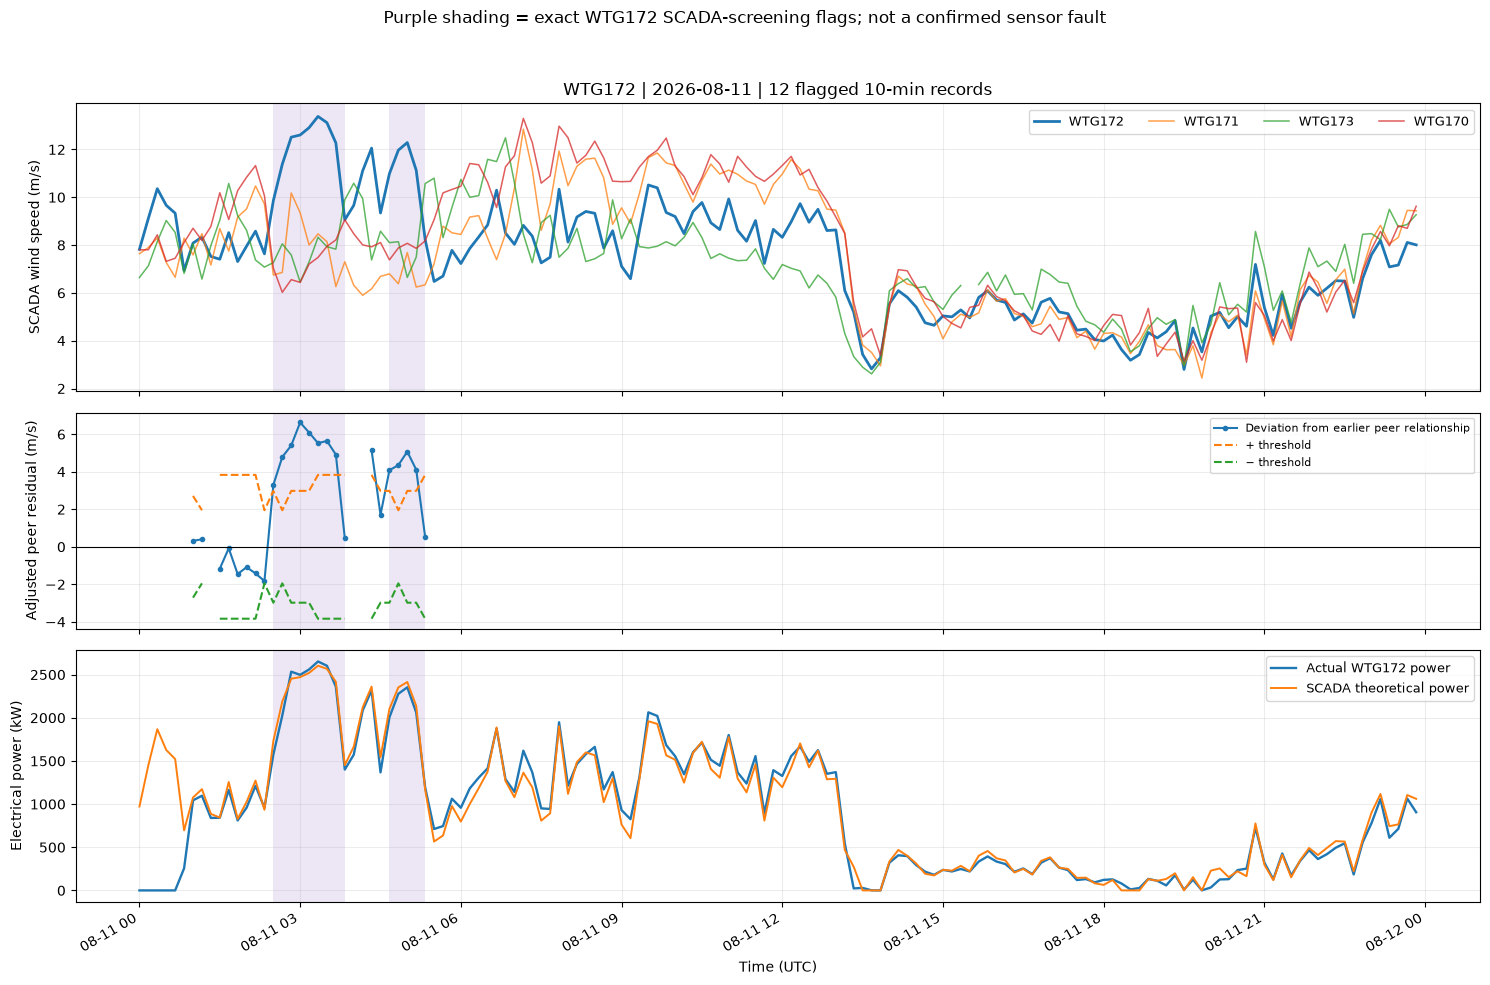

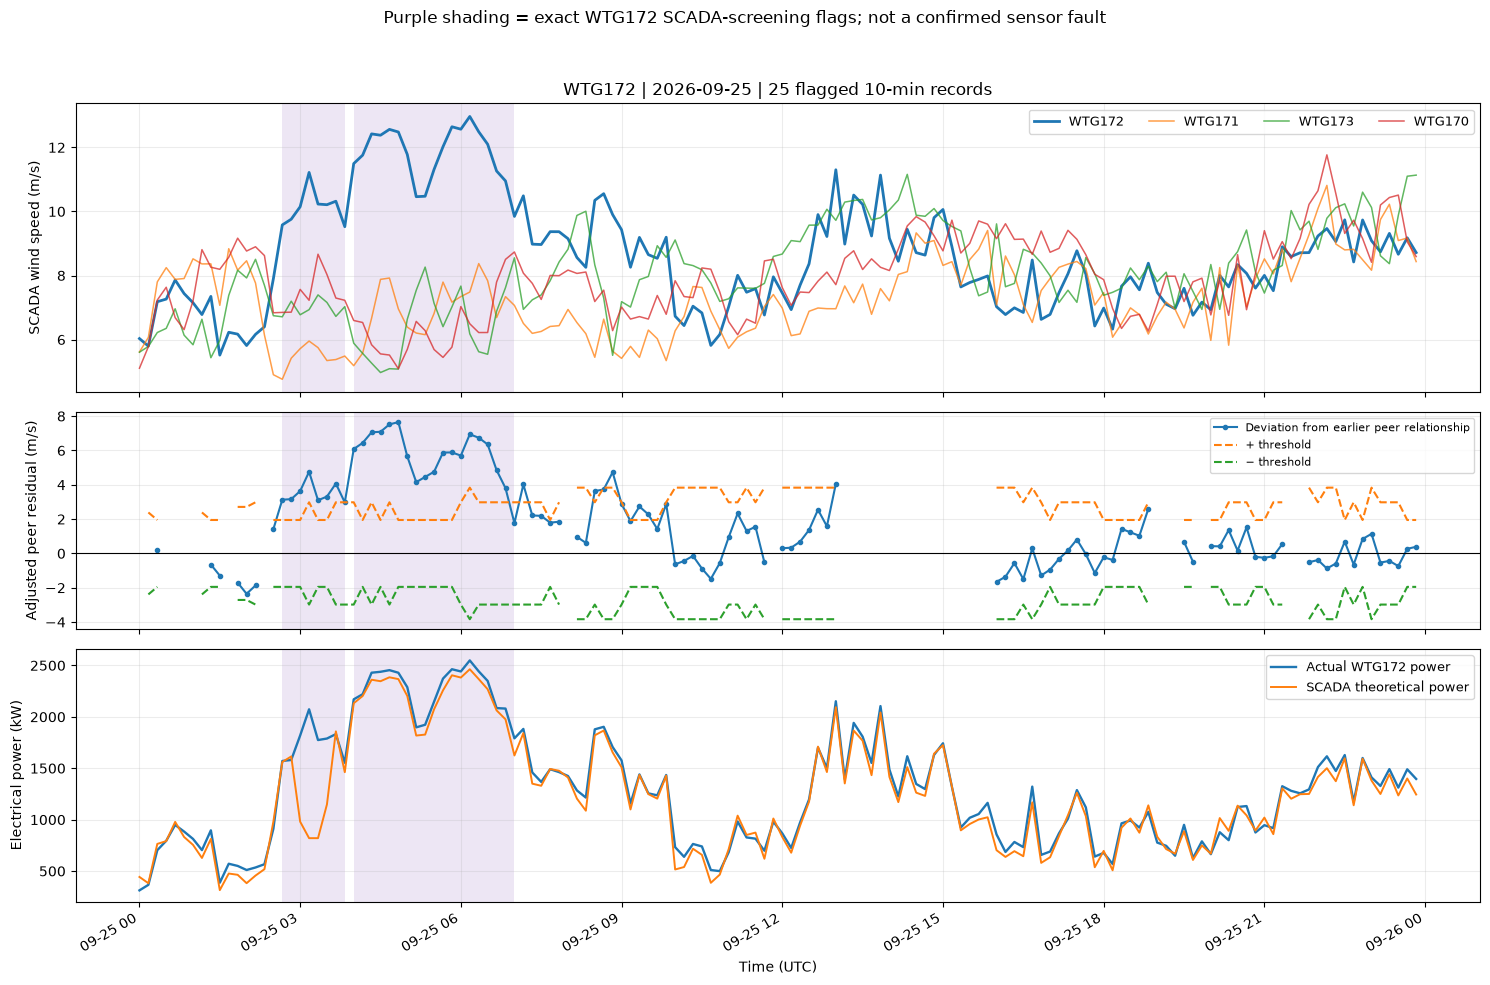


Done. Figures and CSVs saved to: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\09_WTG172_power_flag_overlap
Interpretation: matching anomaly times does not prove the power gap was caused by a wind-speed sensor.
March 2026 is not part of the 08 screening period.


In [24]:
%run -i "09_ALTA10_WTG172_Power_Flag_Overlap.py"

Using screening run: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\08_scada_screening\run_20261029T040948431080Z

Flagged observations: 60
Flagged days: 3
Target: WTG172
Comparison turbines: ['WTG171', 'WTG173', 'WTG170']

Wind-speed source: wind_speed
Actual-power source: KPI_real_power_ac
Theoretical-power source: comparison_theoretical_power

--- Matched observation coverage ---
Flagged observations: 60
Complete four-turbine wind and power comparisons: 60

--- WTG172 vs peers ---


,observations,complete_comparisons,mean_wind_difference_ms,mean_power_difference_kw,pct_WTG172_faster,pct_WTG172_more_power,pct_both_higher
flagged,,,,,,,
Other times on flagged days,372.0,370.0,-0.17,-148.17,42.43,32.43,29.19
Flagged observations,60.0,60.0,4.91,1476.28,100.00,100.00,100.00



--- By flagged day ---


,date,observations,complete_comparisons,mean_wind_difference_ms,mean_power_difference_kw,pct_WTG172_faster,pct_WTG172_more_power,pct_both_higher
0,2026-08-10,23.0,23.0,5.08,1527.73,100.0,100.0,100.0
1,2026-08-11,12.0,12.0,4.55,1354.41,100.0,100.0,100.0
2,2026-09-25,25.0,25.0,4.93,1487.45,100.0,100.0,100.0


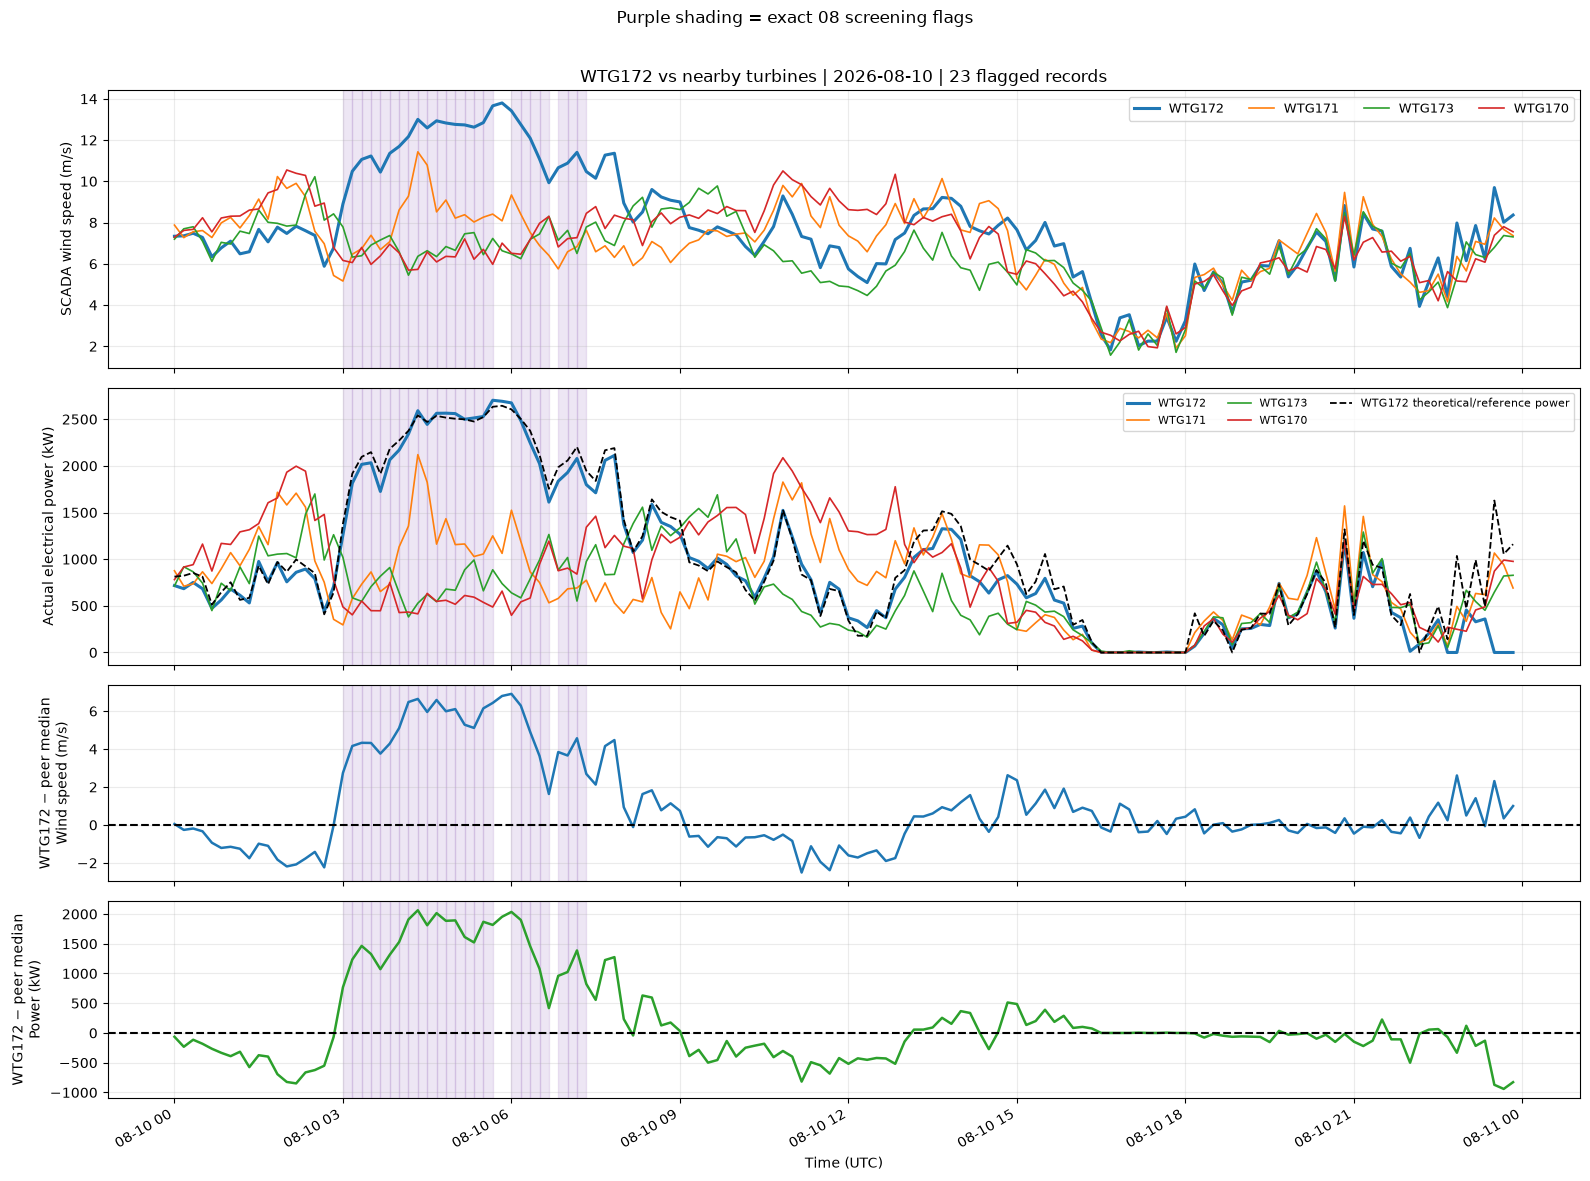

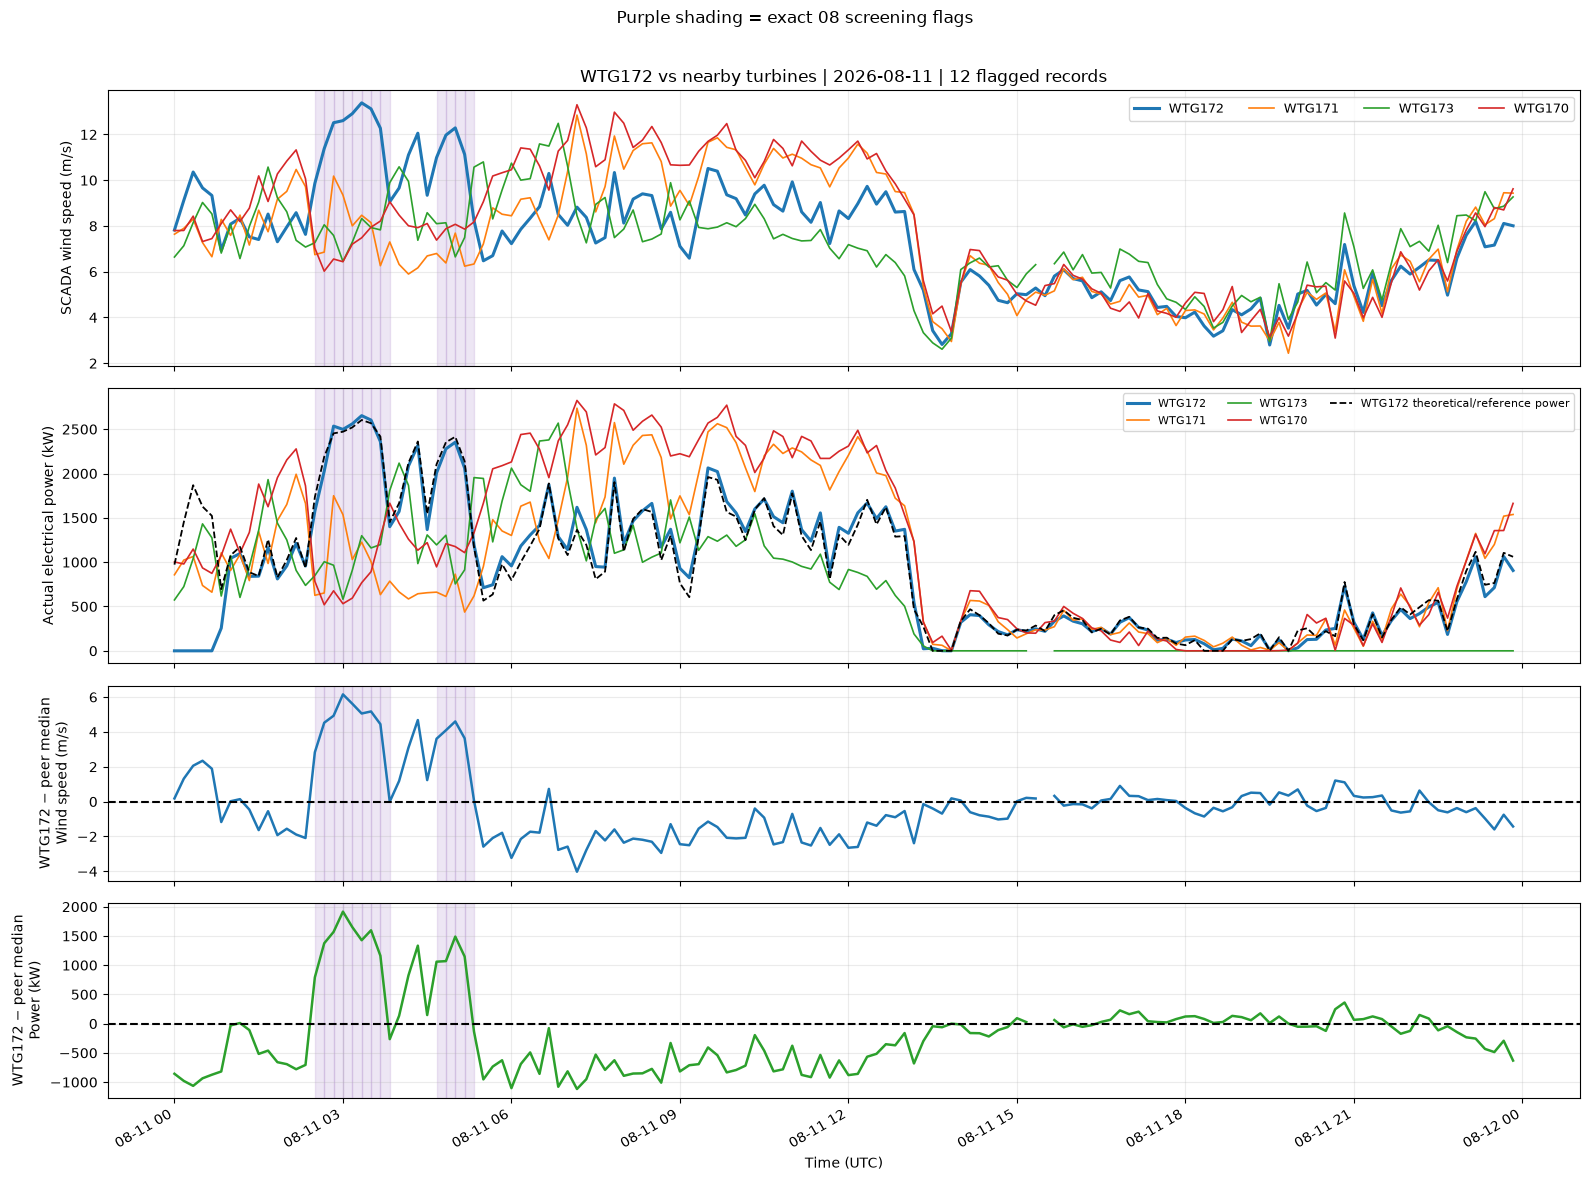

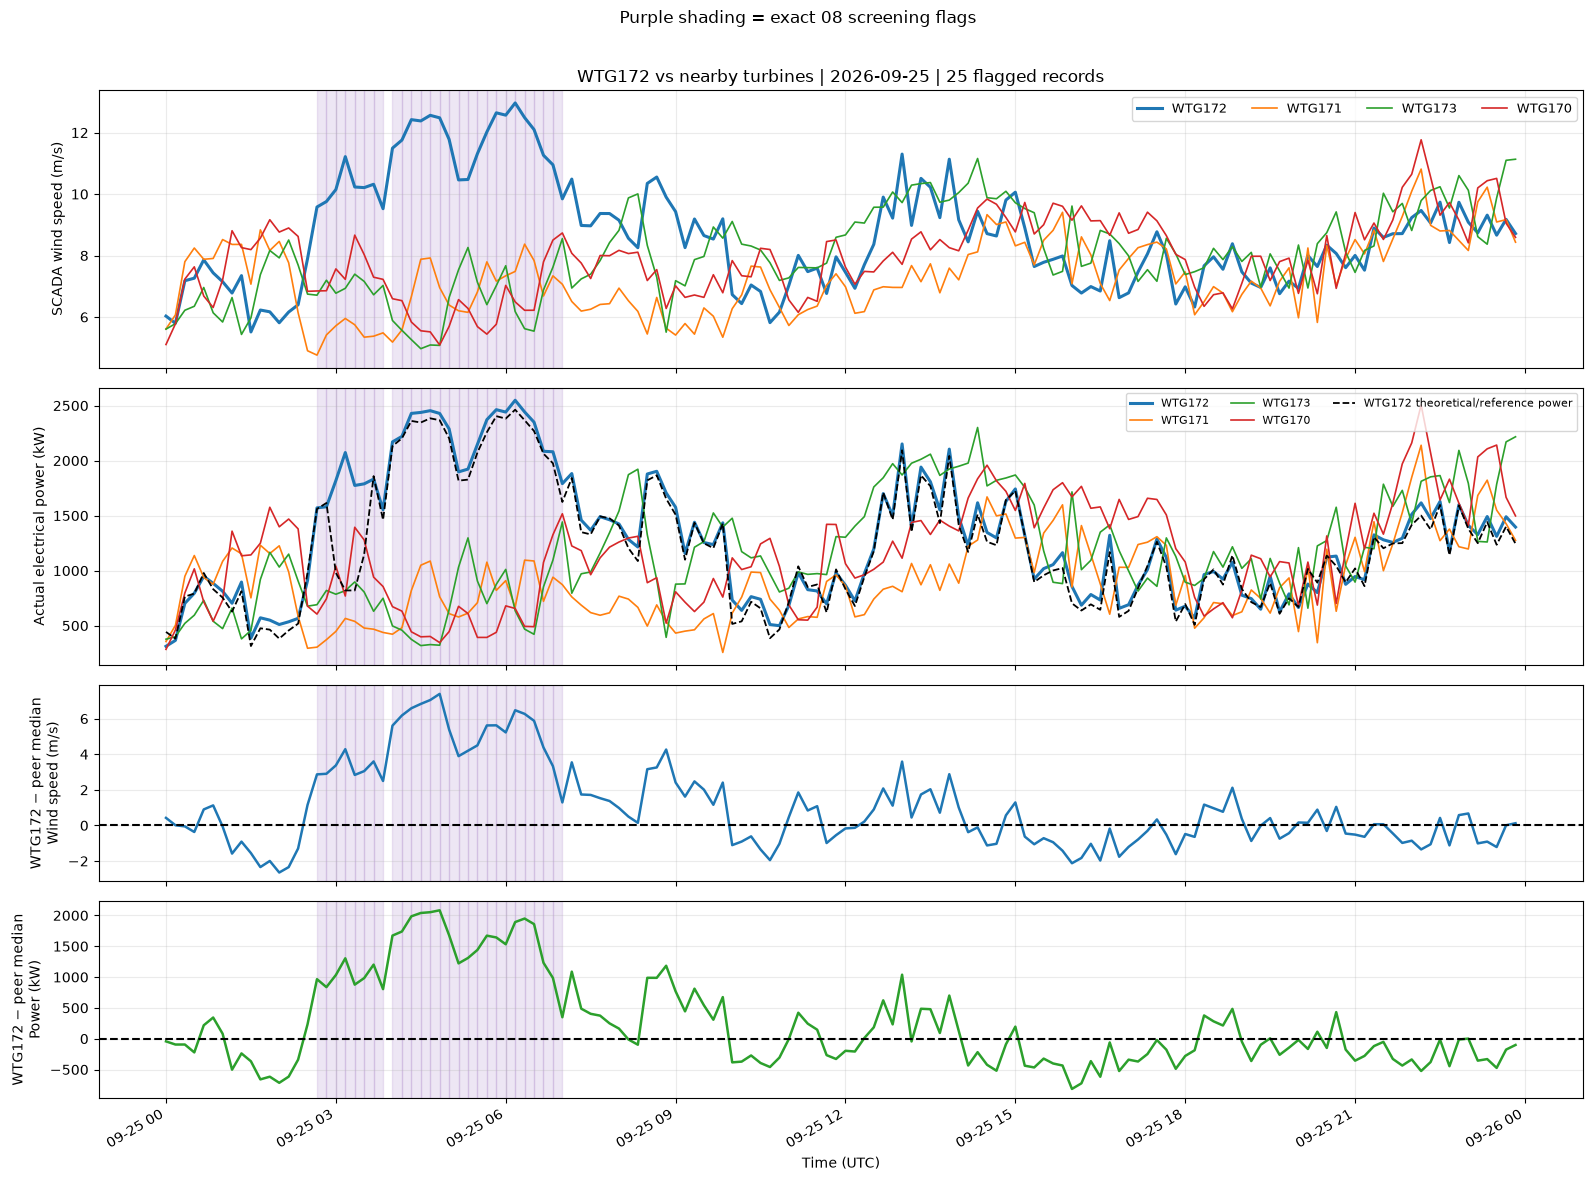

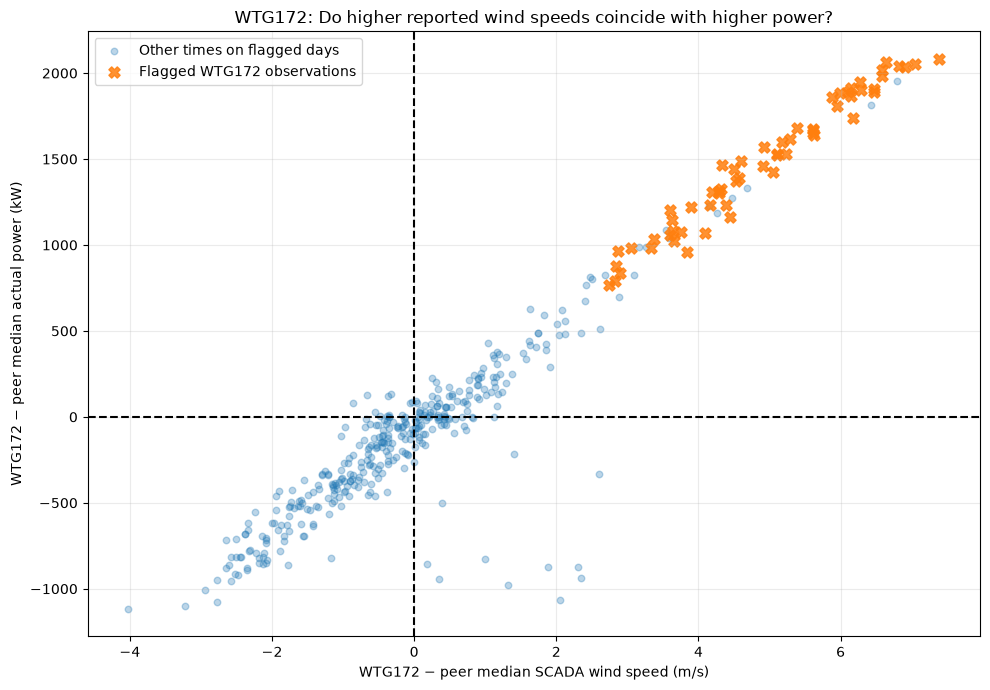


No operating-status or curtailment fields identified.
Normal turbine operation cannot be confirmed from this comparison.

Analysis complete!
Results saved to: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\09_WTG172_power_flag_overlap\peer_wind_power_check
These plots investigate coincident wind and power differences; they do not establish sensor faults.


In [25]:

# ==============================================================
# 09B — WTG172: Compare wind speed and power against nearby turbines
# One complete Jupyter cell
# ==============================================================

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# --------------------------------------------------------------
# 1. Project paths and settings
# --------------------------------------------------------------

TARGET = "WTG172"

PROJECT = (
    Path(PROJECT_ROOT)
    if "PROJECT_ROOT" in globals()
    else Path(
        r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
    )
)

RUNS_FOLDER = PROJECT / "data/processed/08_scada_screening"

OUTPUT = (
    PROJECT
    / "data/processed/09_WTG172_power_flag_overlap"
    / "peer_wind_power_check"
)
OUTPUT.mkdir(parents=True, exist_ok=True)

# Reuse the exact 08 run selected in our previous 09 analysis.
# Otherwise find the newest completed run.
if (
    "run" in globals()
    and isinstance(run, (Path, str))
    and Path(run).is_dir()
):
    screening_run = Path(run)
else:
    candidates = sorted(
        RUNS_FOLDER.glob("run_*"),
        reverse=True
    )

    screening_run = next(
        (
            p for p in candidates
            if (
                p / "08_flagged_episodes.csv"
            ).exists()
            and (
                p / "08_fixed_peers.csv"
            ).exists()
            and (
                p / "intervals/WTG172_screened_intervals.csv"
            ).exists()
        ),
        None
    )

    if screening_run is None:
        raise FileNotFoundError(
            "Could not find a completed 08 screening run."
        )

print("Using screening run:", screening_run)

# --------------------------------------------------------------
# 2. Load exact flagged timestamps
# --------------------------------------------------------------

screen = pd.read_csv(
    screening_run
    / "intervals/WTG172_screened_intervals.csv"
)

screen["timestamp"] = pd.to_datetime(
    screen["timestamp"],
    utc=True,
    errors="coerce"
)

if (
    screen["timestamp"].isna().any()
    or screen["timestamp"].duplicated().any()
):
    raise ValueError(
        "Screening timestamps are missing or duplicated."
    )

def parse_flags(series):
    text = series.astype(str).str.lower().str.strip()

    allowed = ["true", "false", "1", "0", "1.0", "0.0"]

    if not text.isin(allowed).all():
        raise ValueError("Unknown screening flag values.")

    return text.isin(["true", "1", "1.0"])

screen["departure_episode"] = parse_flags(
    screen["departure_episode"]
)

screen["flat_episode"] = parse_flags(
    screen["flat_episode"]
)

if "period" in screen.columns:
    screen = screen[
        screen["period"] == "later_evaluation"
    ].copy()

screen["flagged"] = (
    screen["departure_episode"]
    | screen["flat_episode"]
)

flagged_times = pd.DatetimeIndex(
    screen.loc[screen["flagged"], "timestamp"]
).unique().sort_values()

if len(flagged_times) == 0:
    raise ValueError("No flagged WTG172 observations found.")

flagged_days = pd.DatetimeIndex(
    flagged_times.floor("D").unique()
).sort_values()

print("\nFlagged observations:", len(flagged_times))
print("Flagged days:", len(flagged_days))

# --------------------------------------------------------------
# 3. Identify WTG172's three comparison turbines
# --------------------------------------------------------------

peer_table = pd.read_csv(
    screening_run / "08_fixed_peers.csv"
)

peer_table = peer_table[
    peer_table["turbine"] == TARGET
].sort_values("rank")

peers = peer_table["peer"].tolist()

if len(peers) != 3 or len(set(peers)) != 3:
    raise ValueError(
        "Expected exactly three fixed comparison turbines."
    )

turbines = [TARGET] + peers

print("Target:", TARGET)
print("Comparison turbines:", peers)

# --------------------------------------------------------------
# 4. Load SCADA measurements
# --------------------------------------------------------------

if (
    "scada" in globals()
    and isinstance(scada, pd.DataFrame)
):
    data = scada.copy()
else:
    data = pd.read_parquet(
        PROJECT / "data/processed/scada_data.parquet"
    )

if (
    "turbine" not in data.columns
    and "turbine" in data.index.names
):
    data = data.reset_index()

if (
    "utc" not in data.columns
    and "timestamp" not in data.columns
):
    data = data.reset_index()

def standardize_turbine(value):
    if pd.isna(value):
        return pd.NA

    text = str(value).strip().upper()

    match = re.fullmatch(
        r"(?:(?:WTG[_\s-]*T?|GE)[_\s-]*)?(\d+)(?:\.0)?",
        text
    )

    if not match:
        raise ValueError(
            f"Unrecognized turbine identifier: {value}"
        )

    return f"WTG{int(match.group(1))}"

data["turbine"] = data["turbine"].map(
    standardize_turbine
)

data = data[
    data["turbine"].isin(turbines)
].copy()

time_col = (
    "utc" if "utc" in data.columns
    else "timestamp"
)

data["time_utc"] = pd.to_datetime(
    data[time_col],
    errors="coerce",
    utc=True
)

if (
    data["time_utc"].isna().any()
    or data.duplicated(["time_utc", "turbine"]).any()
):
    raise ValueError(
        "Invalid or duplicate SCADA timestamps."
    )

wind_col = next(
    (
        c for c in ["wind_speed", "KPI_wind_speed"]
        if c in data.columns
    ),
    None
)

power_col = next(
    (
        c for c in ["KPI_real_power_ac", "real_power_ac"]
        if c in data.columns
    ),
    None
)

if wind_col is None or power_col is None:
    raise KeyError("Wind speed or electrical power is missing.")

data["wind_ms"] = pd.to_numeric(
    data[wind_col],
    errors="coerce"
)

data["power_kw"] = pd.to_numeric(
    data[power_col],
    errors="coerce"
)

# Power units must be verified; never infer a conversion.
if data["power_kw"].quantile(0.99) > 5000:
    raise ValueError(
        "Power does not appear to be in kW. Verify units."
    )

# Optional theoretical power from partner notebook
theory_col = next(
    (
        c for c in [
            "comparison_theoretical_power",
            "KPI_theoretical_power",
            "theoretical_power"
        ]
        if c in data.columns
    ),
    None
)

if theory_col:
    data["theory_kw"] = pd.to_numeric(
        data[theory_col],
        errors="coerce"
    )
else:
    data["theory_kw"] = np.nan

print("\nWind-speed source:", wind_col)
print("Actual-power source:", power_col)
print("Theoretical-power source:", theory_col)

# --------------------------------------------------------------
# 5. Build complete ten-minute timelines for flagged days
# --------------------------------------------------------------

full_times = pd.DatetimeIndex([
    timestamp
    for day in flagged_days
    for timestamp in pd.date_range(
        day,
        periods=144,
        freq="10min"
    )
])

wind = data.pivot(
    index="time_utc",
    columns="turbine",
    values="wind_ms"
).reindex(
    index=full_times,
    columns=turbines
)

power = data.pivot(
    index="time_utc",
    columns="turbine",
    values="power_kw"
).reindex(
    index=full_times,
    columns=turbines
)

theory = data.pivot(
    index="time_utc",
    columns="turbine",
    values="theory_kw"
).reindex(
    index=full_times,
    columns=turbines
)

# --------------------------------------------------------------
# 6. Compare WTG172 to the peer median at each timestamp
# --------------------------------------------------------------

comparison = pd.DataFrame(index=full_times)

comparison.index.name = "timestamp"

comparison["flagged"] = (
    comparison.index.isin(flagged_times)
)

for turbine in turbines:
    comparison[f"wind_{turbine}"] = wind[turbine]
    comparison[f"power_{turbine}"] = power[turbine]

comparison["theoretical_172"] = theory[TARGET]

# Require all three peers for a valid peer-median comparison.
comparison["peer_wind_median"] = wind[peers].median(
    axis=1,
    skipna=False
)

comparison["peer_power_median"] = power[peers].median(
    axis=1,
    skipna=False
)

comparison["wind_difference"] = (
    comparison[f"wind_{TARGET}"]
    - comparison["peer_wind_median"]
)

comparison["power_difference"] = (
    comparison[f"power_{TARGET}"]
    - comparison["peer_power_median"]
)

comparison["complete_measurements"] = (
    wind[turbines].notna().all(axis=1)
    & power[turbines].notna().all(axis=1)
)

flagged = comparison[
    comparison["flagged"]
].copy()

print("\n--- Matched observation coverage ---")
print("Flagged observations:", len(flagged))
print(
    "Complete four-turbine wind and power comparisons:",
    int(flagged["complete_measurements"].sum())
)

# --------------------------------------------------------------
# 7. Statistical summaries
# --------------------------------------------------------------

def summarize(group):
    valid = group[group["complete_measurements"]]

    return pd.Series({
        "observations": len(group),
        "complete_comparisons": len(valid),

        "mean_wind_difference_ms":
            valid["wind_difference"].mean(),

        "mean_power_difference_kw":
            valid["power_difference"].mean(),

        "pct_WTG172_faster":
            100 * valid["wind_difference"].gt(0).mean()
            if len(valid) else np.nan,

        "pct_WTG172_more_power":
            100 * valid["power_difference"].gt(0).mean()
            if len(valid) else np.nan,

        "pct_both_higher":
            100 * (
                valid["wind_difference"].gt(0)
                & valid["power_difference"].gt(0)
            ).mean()
            if len(valid) else np.nan
    })

summary = comparison.groupby("flagged").apply(
    summarize
)

summary.index = summary.index.map({
    False: "Other times on flagged days",
    True: "Flagged observations"
})

print("\n--- WTG172 vs peers ---")
display(summary.round(2))

day_summaries = pd.DataFrame([
    {
        "date": day.strftime("%Y-%m-%d"),
        **summarize(
            flagged.loc[
                flagged.index.floor("D") == day
            ]
        ).to_dict()
    }
    for day in flagged_days
])

print("\n--- By flagged day ---")
display(day_summaries.round(2))

# Save all matched data
comparison.reset_index().to_csv(
    OUTPUT / "WTG172_peer_wind_power_all_flagged_days.csv",
    index=False
)

flagged.reset_index().to_csv(
    OUTPUT / "WTG172_exact_flagged_comparisons.csv",
    index=False
)

summary.to_csv(
    OUTPUT / "WTG172_peer_comparison_summary.csv"
)

day_summaries.to_csv(
    OUTPUT / "WTG172_peer_comparison_by_day.csv",
    index=False
)

# --------------------------------------------------------------
# 8. Four-panel plots for each flagged day
# --------------------------------------------------------------

for day in flagged_days:

    daily = comparison[
        comparison.index.floor("D") == day
    ]

    day_flags = flagged_times[
        (flagged_times >= day)
        & (flagged_times < day + pd.Timedelta(days=1))
    ]

    fig, axes = plt.subplots(
        4, 1,
        figsize=(16, 12),
        sharex=True,
        gridspec_kw={
            "height_ratios": [1.2, 1.2, 0.85, 0.85]
        }
    )

    # Panel 1: SCADA wind speeds
    for turbine in turbines:
        axes[0].plot(
            daily.index,
            daily[f"wind_{turbine}"],
            linewidth=2.2 if turbine == TARGET else 1.2,
            label=turbine
        )

    # Panel 2: Actual electrical power
    for turbine in turbines:
        axes[1].plot(
            daily.index,
            daily[f"power_{turbine}"],
            linewidth=2.2 if turbine == TARGET else 1.2,
            label=turbine
        )

    if daily["theoretical_172"].notna().any():
        axes[1].plot(
            daily.index,
            daily["theoretical_172"],
            color="black",
            linestyle="--",
            linewidth=1.3,
            label="WTG172 theoretical/reference power"
        )

    # Panel 3: WTG172 wind speed minus peer median
    axes[2].plot(
        daily.index,
        daily["wind_difference"],
        color="tab:blue",
        linewidth=1.8
    )

    # Panel 4: WTG172 actual power minus peer median
    axes[3].plot(
        daily.index,
        daily["power_difference"],
        color="tab:green",
        linewidth=1.8
    )

    axes[2].axhline(0, color="black", linestyle="--")
    axes[3].axhline(0, color="black", linestyle="--")

    # Highlight exact flagged ten-minute intervals
    for ax in axes:
        for timestamp in day_flags:
            ax.axvspan(
                timestamp,
                timestamp + pd.Timedelta(minutes=10),
                color="tab:purple",
                alpha=0.16
            )

        ax.grid(alpha=0.25)

    axes[0].set_ylabel("SCADA wind speed (m/s)")
    axes[1].set_ylabel("Actual electrical power (kW)")
    axes[2].set_ylabel(
        "WTG172 − peer median\nWind speed (m/s)"
    )
    axes[3].set_ylabel(
        "WTG172 − peer median\nPower (kW)"
    )
    axes[3].set_xlabel("Time (UTC)")

    axes[0].legend(ncol=4, fontsize=9)
    axes[1].legend(ncol=3, fontsize=8)

    axes[0].set_title(
        f"WTG172 vs nearby turbines | {day:%Y-%m-%d}"
        f" | {len(day_flags)} flagged records"
    )

    fig.suptitle(
        "Purple shading = exact 08 screening flags",
        fontsize=12
    )

    fig.autofmt_xdate()
    fig.tight_layout(rect=[0, 0, 1, 0.97])

    fig.savefig(
        OUTPUT / f"WTG172_wind_power_{day:%Y-%m-%d}.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

# --------------------------------------------------------------
# 9. Final figure: Wind-speed difference vs power difference
# --------------------------------------------------------------

complete = comparison[
    comparison["complete_measurements"]
]

normal = complete[
    ~complete["flagged"]
]

flagged_complete = complete[
    complete["flagged"]
]

fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(
    normal["wind_difference"],
    normal["power_difference"],
    alpha=0.30,
    s=22,
    label="Other times on flagged days"
)

ax.scatter(
    flagged_complete["wind_difference"],
    flagged_complete["power_difference"],
    marker="X",
    s=65,
    alpha=0.85,
    label="Flagged WTG172 observations"
)

ax.axhline(0, color="black", linestyle="--")
ax.axvline(0, color="black", linestyle="--")

ax.set_xlabel(
    "WTG172 − peer median SCADA wind speed (m/s)"
)

ax.set_ylabel(
    "WTG172 − peer median actual power (kW)"
)

ax.set_title(
    "WTG172: Do higher reported wind speeds coincide "
    "with higher power?"
)

ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()

fig.savefig(
    OUTPUT / "WTG172_wind_vs_power_differences.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------------------
# 10. Check for available operational-status information
# --------------------------------------------------------------

status_candidates = [
    "KPI_operating_status",
    "operating_status",
    "turbine_status",
    "turbine_state",
    "operating_mode",
    "KPI_operation_mode",
    "curtailment_status",
    "KPI_curtailment",
    "status"
]

available_status = [
    col for col in status_candidates
    if col in data.columns
]

if available_status:

    flagged_status = data[
        (data["turbine"] == TARGET)
        & data["time_utc"].isin(flagged_times)
    ][["time_utc"] + available_status].copy()

    flagged_status.to_csv(
        OUTPUT / "WTG172_flagged_operating_status_UNVERIFIED.csv",
        index=False
    )

    print("\nPossible operating-status columns:")
    print(available_status)

    print(
        "These values need sponsor confirmation "
        "before classifying operation as normal."
    )

else:
    print(
        "\nNo operating-status or curtailment fields identified."
    )
    print(
        "Normal turbine operation cannot be confirmed "
        "from this comparison."
    )

print("\nAnalysis complete!")
print("Results saved to:", OUTPUT)
print(
    "These plots investigate coincident wind and power "
    "differences; they do not establish sensor faults."
)


Using 08 screening run: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\08_scada_screening\run_20261029T040948431080Z

Comparison turbines: ['WTG171', 'WTG173', 'WTG170']
Verified flagged observations: 60

--- WTG172 FLAGGED-DAY RESULTS ---


,day_utc,flagged_intervals,mast_channel3_available,mean_mast_speed_ms,mean_mast_direction_deg,median_mast_direction_difference_hh_deg,mean_WTG172_minus_peer_wind_ms,mean_WTG172_minus_peer_power_kw,max_WTG172_modeled_deficit_pct,max_peer_modeled_deficit_pct,passes_low_wake_screen_all_four,all_3_peer_lidars_available,mean_peer_SCADA_minus_LiDAR_ms
0,2026-08-10,23,23,8.635,296.628,6.838,5.078,1527.726,0.0,0.0,True,9,0.101
1,2026-08-11,12,12,8.478,293.664,6.813,4.555,1354.405,0.0,0.0,True,6,0.014
2,2026-09-25,25,25,8.062,293.581,7.806,4.933,1487.446,0.0,0.0,True,0,NaN



--- NEIGHBORING LiDAR COMPARISONS ---
Source: 06 LiDAR matched dataset


,peer,valid_flagged_lidar_intervals,mean_scada_minus_lidar_ms,median_scada_minus_lidar_ms,median_abs_difference_ms
0,WTG171,24,0.073,0.015,0.251
1,WTG173,25,-0.310,-0.259,0.259
2,WTG170,24,0.064,0.026,0.214



--- WAKE MODEL CHECK ---
Flagged observations where all four turbines pass the <2% screen: 60 out of 60
This is expected because the screening selected low-predicted-wake conditions.


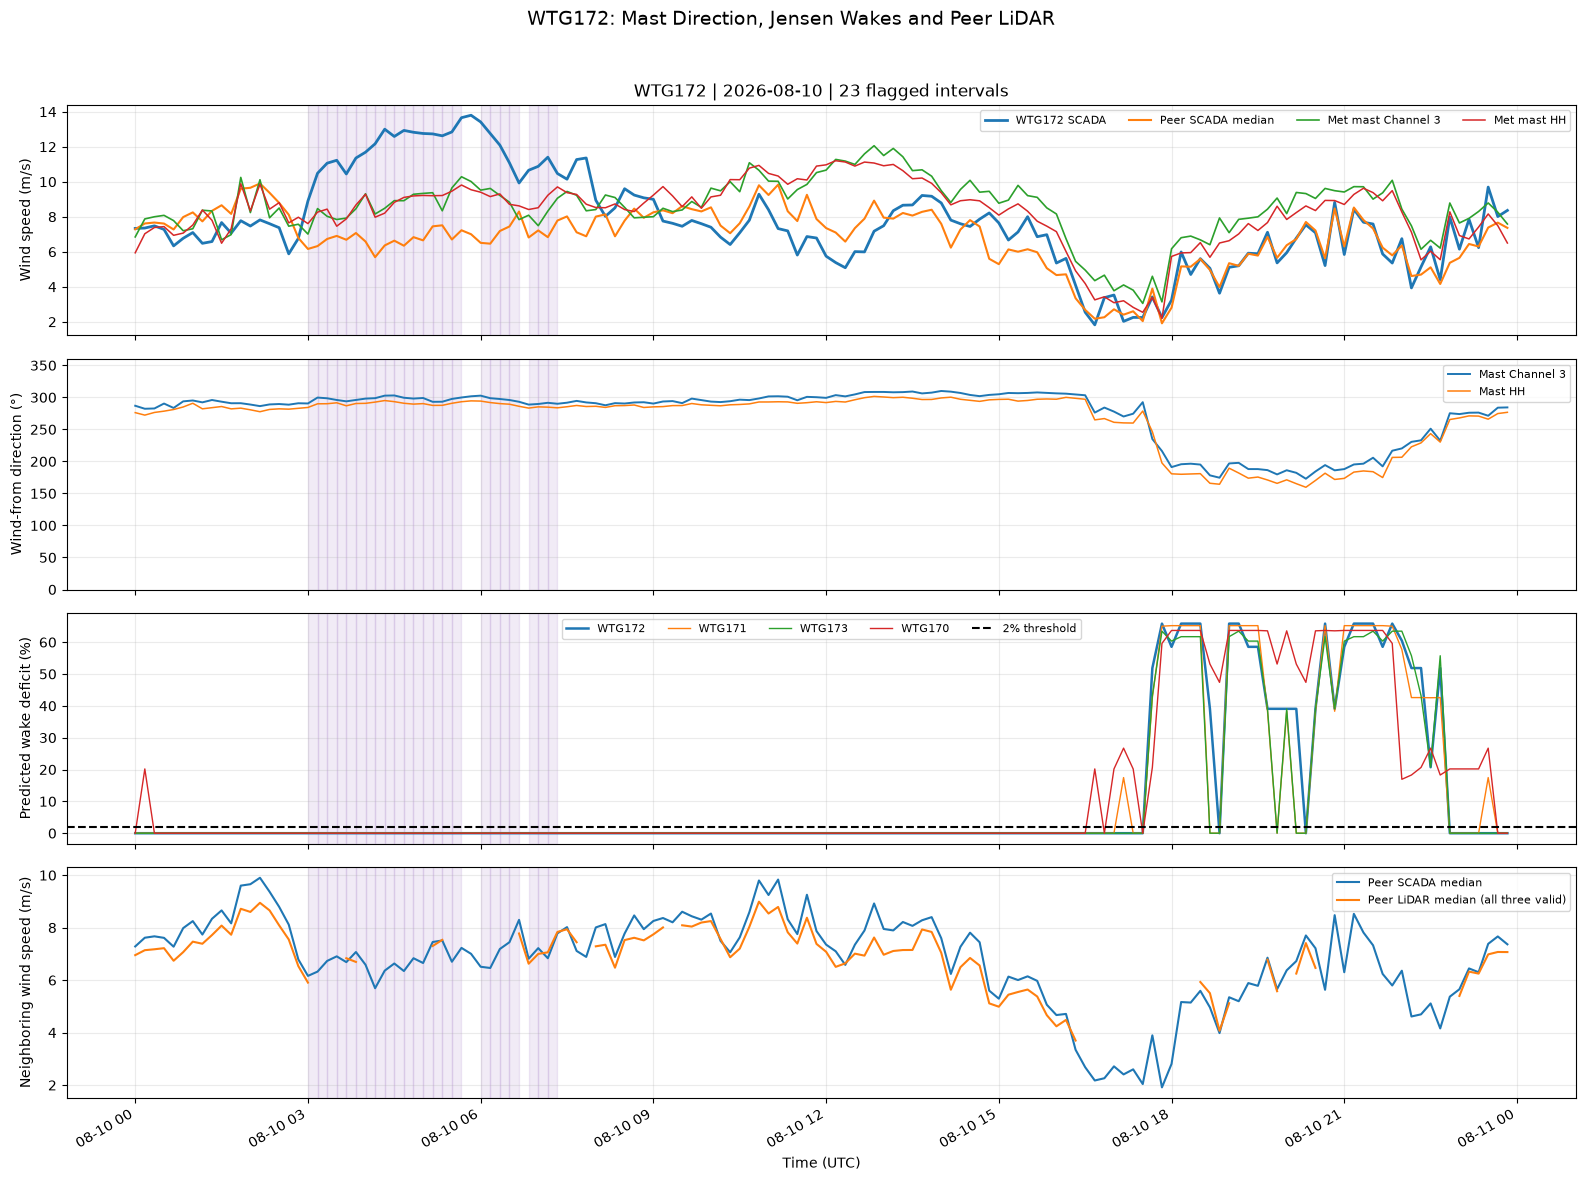

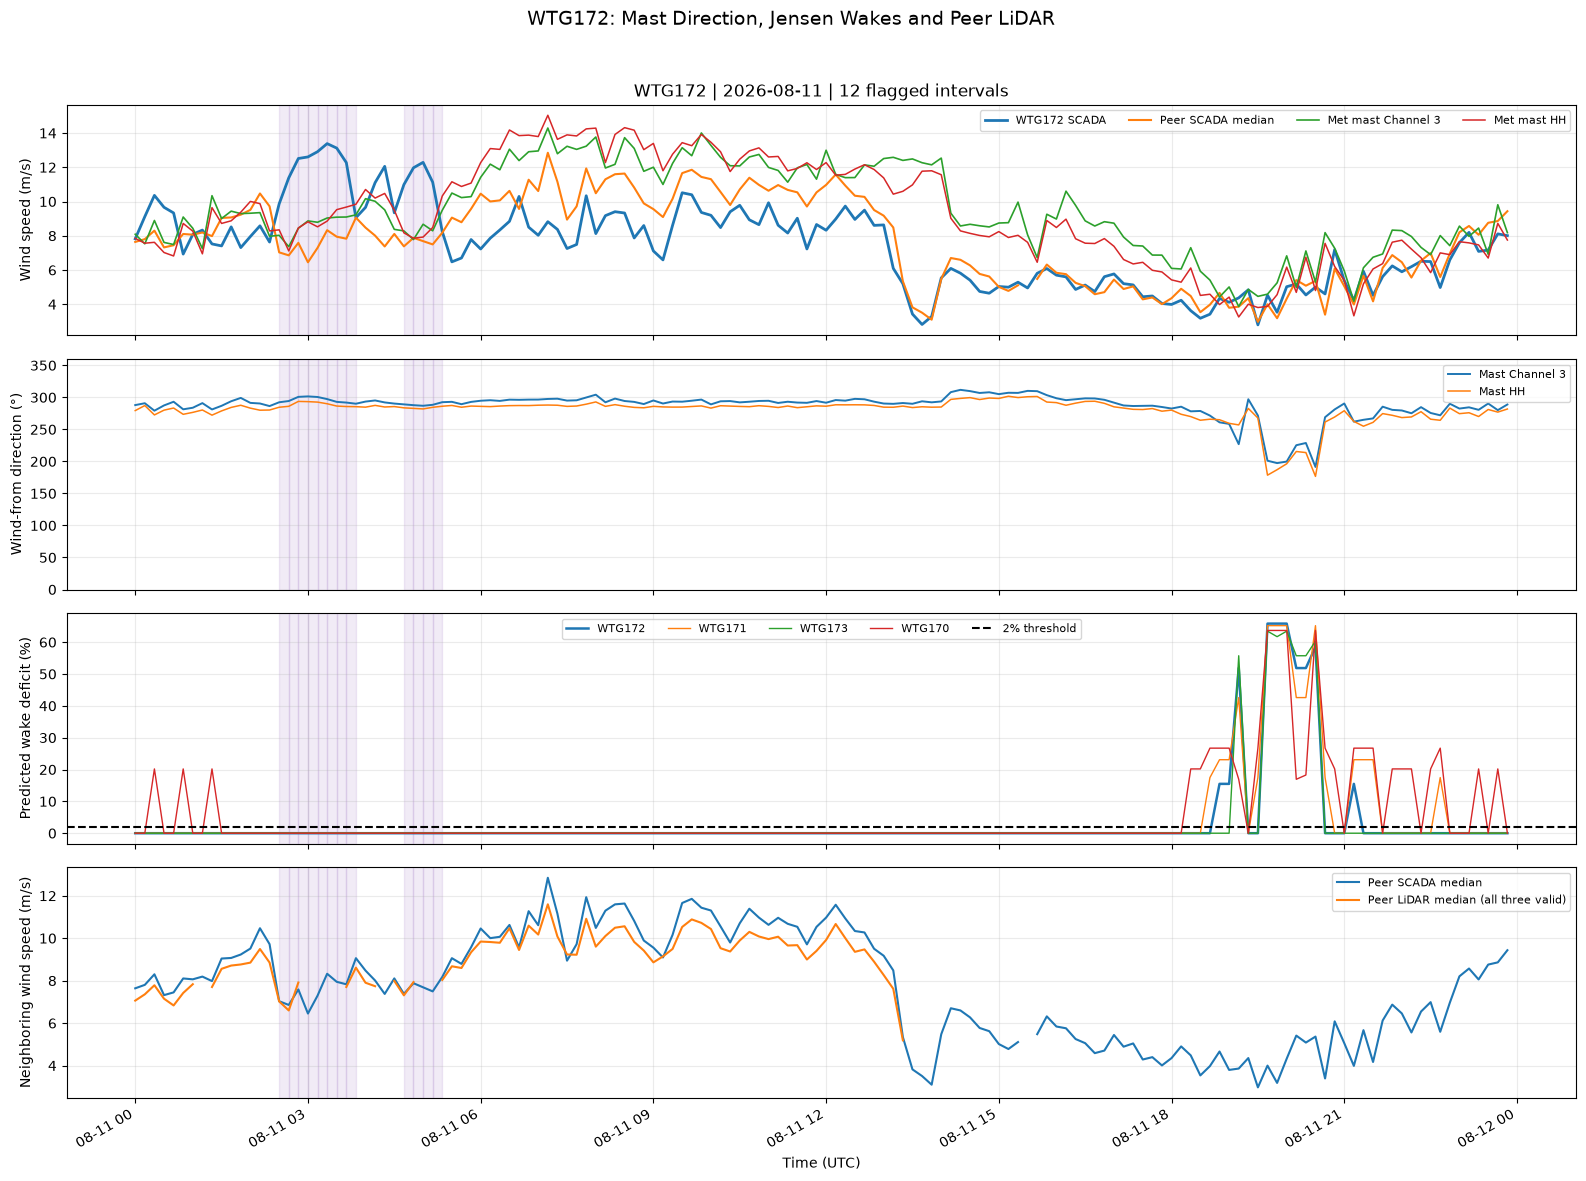

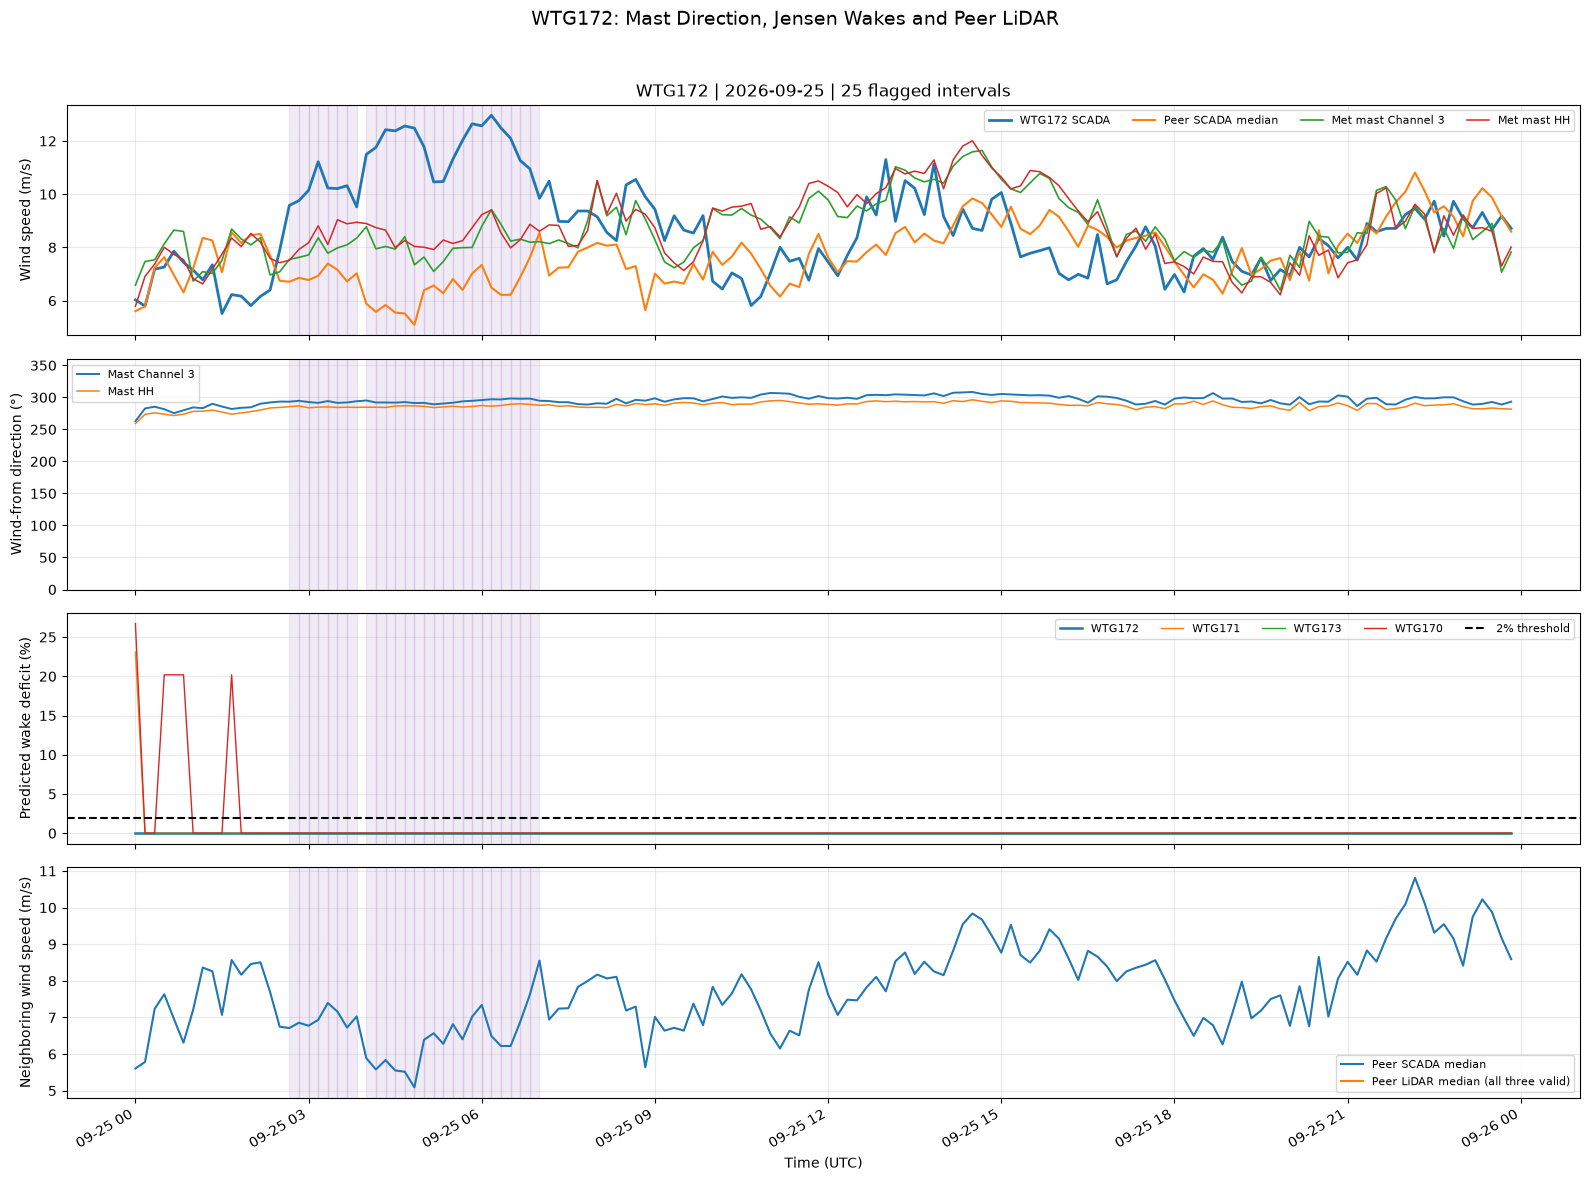


--- WTG172 NEIGHBORING TURBINE GEOMETRY ---


,peer,distance_km,elevation_difference_m
0,WTG171,0.150,-13.505
1,WTG173,0.151,-12.127
2,WTG170,0.305,-24.480


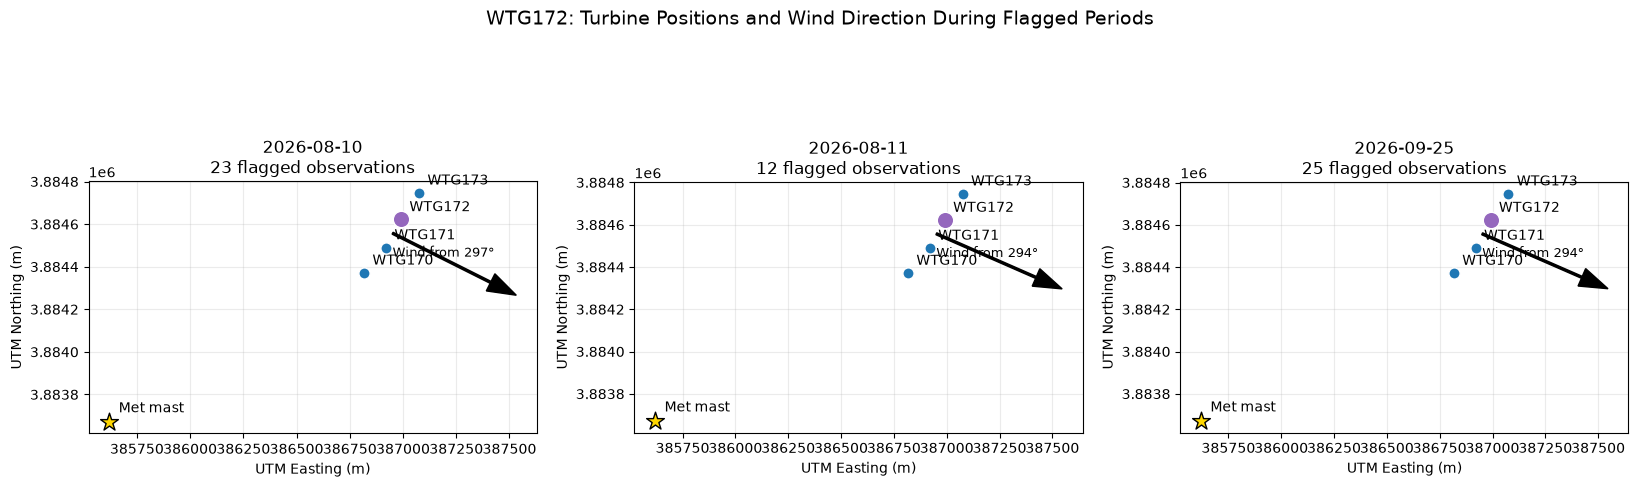


WTG172 INVESTIGATION — ANALYSIS COMPLETE

Flagged observations: 60
Distinct flagged days: 3

Average WTG172 wind-speed difference vs peers:
4.913 m/s

Average WTG172 power difference vs peers:
1476.28 kW

Peer LiDAR measurements are supporting evidence,
not a calibrated reference for WTG172.

Model predictions are preliminary and use fixed
aerodynamic parameters, not observed wake losses.

To confirm a sensor problem, we would still need:
- Validated SCADA wind-speed channel definitions
- Verified turbine status and curtailment records
- WTG172 calibration and maintenance history
- A trusted wind-speed reference near WTG172
- Verified wind directions and timestamp conventions

Results saved to:
C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\09_WTG172_power_flag_overlap\wake_mast_peer_lidar


In [27]:

# ================================================================
# 09C — WTG172: Wake, Met Mast, and Neighboring LiDAR Investigation
# Paste this entire code into ONE NEW JUPYTER CELL after 09B.
# Existing wake models and screening flags are not modified.
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pyproj import Transformer

# ================================================================
# 1. SETTINGS AND FILE LOCATIONS
# ================================================================

ROOT_C = (
    Path(PROJECT_ROOT)
    if "PROJECT_ROOT" in globals()
    else Path(
        r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
    )
)

PREVIOUS_C = (
    ROOT_C
    / "data/processed/09_WTG172_power_flag_overlap/peer_wind_power_check"
)

OUT_C = (
    ROOT_C
    / "data/processed/09_WTG172_power_flag_overlap/wake_mast_peer_lidar"
)

OUT_C.mkdir(parents=True, exist_ok=True)

TARGET_C = "WTG172"

OFFSETS_C = [-10, -5, 0, 5, 10]
LOW_WAKE_PCT_C = 2.0

# Confirmed met mast GPS coordinates
MAST_LAT_C = 35.089338
MAST_LON_C = -118.254800

# ================================================================
# 2. LOCATE THE PREVIOUS 08 SCREENING RUN
# ================================================================

if (
    "RUN_09B" in globals()
    and RUN_09B is not None
    and Path(RUN_09B).is_dir()
):
    RUN_C = Path(RUN_09B)

elif (
    "screening_run" in globals()
    and screening_run is not None
    and Path(screening_run).is_dir()
):
    RUN_C = Path(screening_run)

elif (
    "run" in globals()
    and isinstance(run, (Path, str))
    and Path(run).is_dir()
):
    RUN_C = Path(run)

else:
    candidates_c = sorted(
        (
            ROOT_C / "data/processed/08_scada_screening"
        ).glob("run_*"),
        reverse=True
    )

    RUN_C = next(
        (
            p for p in candidates_c
            if (
                p / "08_jensen_all_turbines.csv"
            ).is_file()
            and (
                p / "08_turbine_geometry.csv"
            ).is_file()
            and (
                p / "08_fixed_peers.csv"
            ).is_file()
            and (
                p / "intervals/WTG172_screened_intervals.csv"
            ).is_file()
        ),
        None
    )

if RUN_C is None:
    raise FileNotFoundError(
        "No completed 08 screening run was found."
    )

print("Using 08 screening run:", RUN_C)

# ================================================================
# 3. LOAD THE PREVIOUS WTG172 WIND / POWER COMPARISON
# ================================================================

# Supports either version of the earlier 09B notebook cell.

paired_path_c = next(
    (
        p for p in [
            PREVIOUS_C / "WTG172_peer_wind_power_all_flagged_days.csv",
            PREVIOUS_C / "WTG172_four_turbines_flagged_days_10min.csv"
        ]
        if p.is_file()
    ),
    None
)

if paired_path_c is None:
    raise FileNotFoundError(
        "Could not locate the previous WTG172 comparison CSV. "
        "Run the 09B notebook cell first."
    )

g = pd.read_csv(paired_path_c, low_memory=False)

# Standardize column names from either 09B version.
rename_c = {
    "flagged": "flagged_08",
    "wind_difference": "wind172_minus_peer_ms",
    "power_difference": "power172_minus_peer_kw",
    "complete_measurements": "complete_both"
}

for turbine in ["WTG172", "WTG170", "WTG171", "WTG173"]:
    rename_c[f"wind_{turbine}"] = f"wind_{turbine}_ms"
    rename_c[f"power_{turbine}"] = f"power_{turbine}_kw"

g = g.rename(
    columns={
        old: new
        for old, new in rename_c.items()
        if old in g.columns and new not in g.columns
    }
)

g["timestamp"] = pd.to_datetime(
    g["timestamp"],
    errors="coerce",
    utc=True
)

if (
    g["timestamp"].isna().any()
    or g["timestamp"].duplicated().any()
):
    raise ValueError(
        "Missing or duplicate WTG172 comparison timestamps."
    )

def as_bool_c(values):
    text = values.astype(str).str.strip().str.lower()

    valid = text.isin([
        "true", "false", "1", "0", "1.0", "0.0"
    ])

    if not valid.all():
        raise ValueError(
            "Unknown or missing Boolean flag values."
        )

    return text.isin(["true", "1", "1.0"])

g["flagged_08"] = as_bool_c(g["flagged_08"])
g = g.set_index("timestamp").sort_index()

# ================================================================
# 4. IDENTIFY WTG172'S THREE FIXED COMPARISON TURBINES
# ================================================================

fixed_peers_c = pd.read_csv(
    RUN_C / "08_fixed_peers.csv"
)

PEERS_C = (
    fixed_peers_c.loc[
        fixed_peers_c["turbine"] == TARGET_C
    ]
    .sort_values("rank")["peer"]
    .tolist()
)

TURBINES_C = [TARGET_C] + PEERS_C

if len(PEERS_C) != 3 or len(set(PEERS_C)) != 3:
    raise ValueError(
        "Expected exactly three WTG172 comparison turbines."
    )

print("\nComparison turbines:", PEERS_C)

# Validate required measurements
for turbine in TURBINES_C:

    for field in [
        f"wind_{turbine}_ms",
        f"power_{turbine}_kw"
    ]:

        if field not in g.columns:
            raise KeyError(f"Missing column: {field}")

        g[field] = pd.to_numeric(
            g[field],
            errors="coerce"
        )

for field in [
    "wind172_minus_peer_ms",
    "power172_minus_peer_kw"
]:
    g[field] = pd.to_numeric(
        g[field],
        errors="coerce"
    )

# ================================================================
# 5. VERIFY EXACT SCREENING FLAGS
# ================================================================

flags_csv_c = pd.read_csv(
    RUN_C / "intervals/WTG172_screened_intervals.csv"
)

flags_csv_c["timestamp"] = pd.to_datetime(
    flags_csv_c["timestamp"],
    errors="coerce",
    utc=True
)

if (
    flags_csv_c["timestamp"].isna().any()
    or flags_csv_c["timestamp"].duplicated().any()
):
    raise ValueError("Invalid or duplicate 08 timestamps.")

actual_flag_c = (
    as_bool_c(flags_csv_c["departure_episode"])
    | as_bool_c(flags_csv_c["flat_episode"])
)

if "period" in flags_csv_c.columns:
    actual_flag_c &= (
        flags_csv_c["period"] == "later_evaluation"
    )

expected_flags_c = set(
    flags_csv_c.loc[
        actual_flag_c, "timestamp"
    ]
)

observed_flags_c = set(
    g.index[g["flagged_08"]]
)

if expected_flags_c != observed_flags_c:
    raise ValueError(
        "The 09B flags do not match the selected 08 run. "
        "Check that both analyses use the same screening folder."
    )

print("Verified flagged observations:", len(observed_flags_c))

# ================================================================
# 6. ADD MET MAST WIND SPEED AND DIRECTION
# ================================================================

mast = pd.read_parquet(
    ROOT_C / "data/processed/metmasts_data.parquet"
)

if not any(
    col in mast.columns for col in ["utc", "timestamp"]
):
    mast = mast.reset_index()

time_col_c = (
    "utc" if "utc" in mast.columns
    else "timestamp"
)

mast["timestamp"] = pd.to_datetime(
    mast[time_col_c],
    errors="coerce",
    utc=True
)

if (
    mast["timestamp"].isna().any()
    or mast["timestamp"].duplicated().any()
):
    raise ValueError(
        "Met mast timestamps are missing or duplicated."
    )

mast_columns_c = [
    "mm_wind_speed_3",
    "mm_wind_direction_3",
    "mm_wind_speed_hh",
    "mm_wind_direction_hh"
]

for col in mast_columns_c:

    if col not in mast.columns:
        mast[col] = np.nan

    mast[col] = pd.to_numeric(
        mast[col],
        errors="coerce"
    )

mast = (
    mast.set_index("timestamp")[mast_columns_c]
    .reindex(g.index)
)

g = g.join(mast)

for col in [
    "mm_wind_direction_3",
    "mm_wind_direction_hh"
]:
    g.loc[
        ~g[col].between(0, 360),
        col
    ] = np.nan

for col in [
    "mm_wind_speed_3",
    "mm_wind_speed_hh"
]:
    g.loc[
        ~g[col].between(0, 40),
        col
    ] = np.nan

valid_direction_c = g[
    "mm_wind_direction_3"
].between(0, 360)

# ================================================================
# 7. LOAD EXISTING JENSEN WAKE PREDICTIONS
# ================================================================

wake_lookup_c = pd.read_csv(
    RUN_C / "08_jensen_all_turbines.csv"
)

wake_lookup_c["wind_from_deg"] = pd.to_numeric(
    wake_lookup_c["wind_from_deg"],
    errors="coerce"
)

wake_lookup_c["predicted_deficit_pct"] = pd.to_numeric(
    wake_lookup_c["predicted_deficit_pct"],
    errors="coerce"
)

if wake_lookup_c.duplicated([
    "turbine", "wind_from_deg"
]).any():
    raise ValueError("Duplicate wake lookup entries.")

wake_grid_c = (
    wake_lookup_c.pivot(
        index="wind_from_deg",
        columns="turbine",
        values="predicted_deficit_pct"
    )
    .reindex(
        index=np.arange(0, 360, 5),
        columns=TURBINES_C
    )
)

wake_matrix_c = wake_grid_c.to_numpy(dtype=float)

if not np.isfinite(wake_matrix_c).all():
    raise ValueError(
        "Incomplete wake predictions for the four turbines."
    )

# ================================================================
# 8. MATCH WIND DIRECTION TO THE WAKE MODEL
# ================================================================

safe_angle_c = g[
    "mm_wind_direction_3"
].where(valid_direction_c, 0).to_numpy()

model_checks_c = []

for offset in OFFSETS_C:

    angle_index = (
        np.floor(
            ((safe_angle_c + offset) % 360 + 2.5) / 5
        ).astype(int) % 72
    )

    model_checks_c.append(
        wake_matrix_c[angle_index, :]
    )

model_stack_c = np.stack(
    model_checks_c,
    axis=0
)

for j, turbine in enumerate(TURBINES_C):

    g[f"jensen_nominal_{turbine}_pct"] = np.where(
        valid_direction_c,
        model_checks_c[OFFSETS_C.index(0)][:, j],
        np.nan
    )

    g[f"jensen_max_{turbine}_pct"] = np.where(
        valid_direction_c,
        model_stack_c[:, :, j].max(axis=0),
        np.nan
    )

g["jensen_peer_median_pct"] = g[
    [
        f"jensen_nominal_{peer}_pct"
        for peer in PEERS_C
    ]
].median(axis=1, skipna=False)

g["jensen_172_minus_peer_pctpts"] = (
    g[f"jensen_nominal_{TARGET_C}_pct"]
    - g["jensen_peer_median_pct"]
)

g["all_four_under_2pct"] = g[
    [
        f"jensen_max_{t}_pct"
        for t in TURBINES_C
    ]
].lt(LOW_WAKE_PCT_C).all(axis=1)

# ================================================================
# 9. ADD AVAILABLE NEIGHBORING LiDAR MEASUREMENTS
# ================================================================

lidar_file_c = (
    ROOT_C
    / "data/processed/06_research_synthesis/05_scada_lidar_matched.csv"
)

if lidar_file_c.is_file():

    lidar_raw_c = pd.read_csv(
        lidar_file_c,
        usecols=lambda col: col in {
            "timestamp",
            "utc",
            "turbine",
            "lidar_speed",
            "flagged_interval"
        },
        low_memory=False
    )

    lidar_time_col_c = (
        "timestamp"
        if "timestamp" in lidar_raw_c.columns
        else "utc"
    )

    lidar_raw_c["timestamp"] = pd.to_datetime(
        lidar_raw_c[lidar_time_col_c],
        errors="coerce",
        utc=True
    )

    lidar_raw_c = lidar_raw_c[
        lidar_raw_c["turbine"].isin(PEERS_C)
    ].copy()

    if (
        lidar_raw_c["timestamp"].isna().any()
        or lidar_raw_c.duplicated([
            "timestamp", "turbine"
        ]).any()
    ):
        raise ValueError(
            "Invalid or duplicated LiDAR measurements."
        )

    lidar_raw_c["lidar_speed"] = pd.to_numeric(
        lidar_raw_c["lidar_speed"],
        errors="coerce"
    )

    # Exclude existing 06 anomaly-flagged intervals
    if "flagged_interval" in lidar_raw_c.columns:

        lidar_flags = (
            lidar_raw_c["flagged_interval"]
            .astype(str)
            .str.strip()
            .str.lower()
        )

        valid_flags = lidar_flags.isin([
            "true", "false", "1", "0", "1.0", "0.0"
        ])

        lidar_raw_c.loc[
            ~valid_flags
            | lidar_flags.isin(["true", "1", "1.0"]),
            "lidar_speed"
        ] = np.nan

    lidar_raw_c.loc[
        ~lidar_raw_c["lidar_speed"].between(3, 25),
        "lidar_speed"
    ] = np.nan

    lidar_wide_c = (
        lidar_raw_c.pivot(
            index="timestamp",
            columns="turbine",
            values="lidar_speed"
        )
        .reindex(
            index=g.index,
            columns=PEERS_C
        )
    )

    lidar_source_c = "06 LiDAR matched dataset"

else:

    lidar_wide_c = pd.DataFrame(
        np.nan,
        index=g.index,
        columns=PEERS_C
    )

    lidar_source_c = "LiDAR dataset unavailable"

# Calculate SCADA versus LiDAR differences at neighboring sites

for peer in PEERS_C:

    g[f"lidar_{peer}_ms"] = lidar_wide_c[peer]

    g[f"scada_minus_lidar_{peer}_ms"] = (
        g[f"wind_{peer}_ms"]
        - g[f"lidar_{peer}_ms"]
    )

g["peer_lidar_median_all3_ms"] = (
    lidar_wide_c.median(
        axis=1,
        skipna=False
    )
)

g["peer_scada_median_all3_ms"] = g[
    [
        f"wind_{peer}_ms"
        for peer in PEERS_C
    ]
].median(axis=1, skipna=False)

g["peer_scada_minus_lidar_med_ms"] = (
    g["peer_scada_median_all3_ms"]
    - g["peer_lidar_median_all3_ms"]
)

# ================================================================
# 10. SUMMARIZE EXACT FLAGGED OBSERVATIONS
# ================================================================

f = g[g["flagged_08"]].copy()

if f.empty:
    raise ValueError(
        "No flagged WTG172 observations were found."
    )

def circular_mean_c(values):

    a = pd.to_numeric(
        values,
        errors="coerce"
    ).dropna().to_numpy(dtype=float)

    a = a[(a >= 0) & (a <= 360)]

    if len(a) == 0:
        return np.nan

    radians = np.deg2rad(a)

    mean_angle = np.arctan2(
        np.sin(radians).mean(),
        np.cos(radians).mean()
    )

    return float(
        np.rad2deg(mean_angle) % 360
    )

def circular_absolute_difference_c(a, b):
    return np.abs(
        (a - b + 180) % 360 - 180
    )

# ------------------------------------------------
# Neighboring LiDAR summary
# ------------------------------------------------

peer_lidar_rows_c = []

for peer in PEERS_C:

    values = f[
        f"scada_minus_lidar_{peer}_ms"
    ].dropna()

    peer_lidar_rows_c.append({
        "peer": peer,
        "valid_flagged_lidar_intervals": len(values),
        "mean_scada_minus_lidar_ms": values.mean(),
        "median_scada_minus_lidar_ms": values.median(),
        "median_abs_difference_ms": values.abs().median()
    })

peer_lidar_summary_c = pd.DataFrame(
    peer_lidar_rows_c
)

# ------------------------------------------------
# Flagged day summary
# ------------------------------------------------

report_rows_c = []

for date, sub in f.groupby(f.index.floor("D")):

    day_result = {
        "day_utc": date.strftime("%Y-%m-%d"),
        "flagged_intervals": len(sub),

        "mast_channel3_available":
            int(sub["mm_wind_speed_3"].notna().sum()),

        "mean_mast_speed_ms":
            sub["mm_wind_speed_3"].mean(),

        "mean_mast_direction_deg":
            circular_mean_c(
                sub["mm_wind_direction_3"]
            ),

        "median_mast_direction_difference_hh_deg":
            circular_absolute_difference_c(
                sub["mm_wind_direction_3"],
                sub["mm_wind_direction_hh"]
            ).median(),

        "mean_WTG172_minus_peer_wind_ms":
            sub["wind172_minus_peer_ms"].mean(),

        "mean_WTG172_minus_peer_power_kw":
            sub["power172_minus_peer_kw"].mean(),

        "max_WTG172_modeled_deficit_pct":
            sub[f"jensen_max_{TARGET_C}_pct"].max(),

        "max_peer_modeled_deficit_pct":
            sub[
                [
                    f"jensen_max_{peer}_pct"
                    for peer in PEERS_C
                ]
            ].max().max(),

        "passes_low_wake_screen_all_four":
            bool(sub["all_four_under_2pct"].all()),

        "all_3_peer_lidars_available":
            int(
                sub["peer_lidar_median_all3_ms"]
                .notna()
                .sum()
            ),

        "mean_peer_SCADA_minus_LiDAR_ms":
            sub[
                "peer_scada_minus_lidar_med_ms"
            ].mean()
    }

    report_rows_c.append(day_result)

report_c = pd.DataFrame(
    report_rows_c
)

print("\n--- WTG172 FLAGGED-DAY RESULTS ---")
display(report_c.round(3))

print("\n--- NEIGHBORING LiDAR COMPARISONS ---")
print("Source:", lidar_source_c)
display(peer_lidar_summary_c.round(3))

print("\n--- WAKE MODEL CHECK ---")

print(
    "Flagged observations where all four turbines "
    "pass the <2% screen:",
    int(f["all_four_under_2pct"].sum()),
    "out of",
    len(f)
)

print(
    "This is expected because the screening selected "
    "low-predicted-wake conditions."
)

if int(f["all_four_under_2pct"].sum()) != len(f):
    raise ValueError(
        "Some flags do not meet their original wake screen. "
        "Check that the 08 run and wake lookup match."
    )

# Save auditable results
g.reset_index().to_csv(
    OUT_C / "WTG172_wake_mast_lidar_all_flagged_days.csv",
    index=False
)

report_c.to_csv(
    OUT_C / "WTG172_flagged_day_diagnostics.csv",
    index=False
)

peer_lidar_summary_c.to_csv(
    OUT_C / "WTG172_neighboring_lidar_summary.csv",
    index=False
)

# ================================================================
# 11. GRAPH EACH FLAGGED DAY
# ================================================================

for date, sub in g.groupby(g.index.floor("D")):

    selected = sub[sub["flagged_08"]]

    if selected.empty:
        continue

    fig, axes = plt.subplots(
        4, 1,
        figsize=(16, 12),
        sharex=True
    )

    # Panel 1: Wind speed comparisons
    axes[0].plot(
        sub.index,
        sub[f"wind_{TARGET_C}_ms"],
        label="WTG172 SCADA",
        linewidth=2
    )

    axes[0].plot(
        sub.index,
        sub["peer_scada_median_all3_ms"],
        label="Peer SCADA median",
        linewidth=1.5
    )

    axes[0].plot(
        sub.index,
        sub["mm_wind_speed_3"],
        label="Met mast Channel 3",
        linewidth=1.2
    )

    if sub["mm_wind_speed_hh"].notna().any():
        axes[0].plot(
            sub.index,
            sub["mm_wind_speed_hh"],
            label="Met mast HH",
            linewidth=1.1
        )

    axes[0].set_ylabel("Wind speed (m/s)")
    axes[0].legend(ncol=4, fontsize=8)

    # Panel 2: Observed incoming wind direction
    axes[1].plot(
        sub.index,
        sub["mm_wind_direction_3"],
        label="Mast Channel 3",
        linewidth=1.4
    )

    if sub["mm_wind_direction_hh"].notna().any():
        axes[1].plot(
            sub.index,
            sub["mm_wind_direction_hh"],
            label="Mast HH",
            linewidth=1.1
        )

    axes[1].set_ylabel("Wind-from direction (°)")
    axes[1].set_ylim(0, 360)
    axes[1].legend(fontsize=8)

    # Panel 3: Model predictions for all four turbines
    for turbine in TURBINES_C:

        axes[2].plot(
            sub.index,
            sub[f"jensen_max_{turbine}_pct"],
            label=turbine,
            linewidth=1.8 if turbine == TARGET_C else 1.0
        )

    axes[2].axhline(
        LOW_WAKE_PCT_C,
        linestyle="--",
        color="black",
        label="2% threshold"
    )

    axes[2].set_ylabel("Predicted wake deficit (%)")
    axes[2].legend(ncol=5, fontsize=8)

    # Panel 4: Neighboring SCADA versus LiDAR
    axes[3].plot(
        sub.index,
        sub["peer_scada_median_all3_ms"],
        label="Peer SCADA median",
        linewidth=1.5
    )

    axes[3].plot(
        sub.index,
        sub["peer_lidar_median_all3_ms"],
        label="Peer LiDAR median (all three valid)",
        linewidth=1.5
    )

    axes[3].set_ylabel("Neighboring wind speed (m/s)")
    axes[3].set_xlabel("Time (UTC)")
    axes[3].legend(fontsize=8)

    # Highlight WTG172 screening events
    for ax in axes:

        for stamp in selected.index:
            ax.axvspan(
                stamp,
                stamp + pd.Timedelta(minutes=10),
                color="tab:purple",
                alpha=0.13
            )

        ax.grid(alpha=0.25)

    axes[0].set_title(
        f"WTG172 | {date:%Y-%m-%d} | "
        f"{len(selected)} flagged intervals"
    )

    fig.suptitle(
        "WTG172: Mast Direction, Jensen Wakes and Peer LiDAR",
        fontsize=14
    )

    fig.autofmt_xdate()
    fig.tight_layout(rect=[0, 0, 1, 0.96])

    fig.savefig(
        OUT_C / f"WTG172_wake_mast_lidar_{date:%Y-%m-%d}.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

# ================================================================
# 12. GEOGRAPHICAL COMPARISON
# ================================================================

geometry_c = pd.read_csv(
    RUN_C / "08_turbine_geometry.csv"
)

geometry_c = (
    geometry_c.set_index("turbine")
    .loc[TURBINES_C]
)

required_geo_c = ["x", "y", "elevation_m"]

if not all(
    field in geometry_c.columns
    for field in required_geo_c
):
    raise KeyError(
        "Missing UTM coordinates or elevations."
    )

# Convert confirmed mast location to UTM Zone 11N
transformer_c = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32611",
    always_xy=True
)

mast_e_c, mast_n_c = transformer_c.transform(
    MAST_LON_C,
    MAST_LAT_C
)

target_geo_c = geometry_c.loc[TARGET_C]

distance_rows_c = []

for peer in PEERS_C:

    peer_geo_c = geometry_c.loc[peer]

    distance_rows_c.append({
        "peer": peer,

        "distance_km": np.hypot(
            peer_geo_c["x"] - target_geo_c["x"],
            peer_geo_c["y"] - target_geo_c["y"]
        ) / 1000,

        "elevation_difference_m":
            peer_geo_c["elevation_m"]
            - target_geo_c["elevation_m"]
    })

distances_c = pd.DataFrame(
    distance_rows_c
)

print("\n--- WTG172 NEIGHBORING TURBINE GEOMETRY ---")
display(distances_c.round(3))

distances_c.to_csv(
    OUT_C / "WTG172_neighboring_turbine_geometry.csv",
    index=False
)

# Map the three flagged-day wind directions
fig, axes = plt.subplots(
    1,
    len(report_c),
    figsize=(5.5 * len(report_c), 5.5),
    squeeze=False
)

for ax, row in zip(
    axes.flat,
    report_c.itertuples(index=False)
):

    for turbine in TURBINES_C:

        xy = geometry_c.loc[turbine]

        color = (
            "tab:purple"
            if turbine == TARGET_C
            else "tab:blue"
        )

        ax.scatter(
            xy["x"],
            xy["y"],
            s=140 if turbine == TARGET_C else 65,
            color=color,
            edgecolor="white",
            zorder=5
        )

        ax.annotate(
            turbine,
            (xy["x"], xy["y"]),
            xytext=(6, 6),
            textcoords="offset points"
        )

    # Met mast
    ax.scatter(
        mast_e_c,
        mast_n_c,
        marker="*",
        color="gold",
        edgecolor="black",
        s=180,
        zorder=7
    )

    ax.annotate(
        "Met mast",
        (mast_e_c, mast_n_c),
        xytext=(7, 7),
        textcoords="offset points"
    )

    # Show mean wind-flow direction
    # Meteorological direction indicates where wind COMES FROM.
    # Arrow indicates where wind is flowing TOWARD.
    direction_deg = row.mean_mast_direction_deg

    if np.isfinite(direction_deg):

        theta = np.deg2rad(direction_deg)

        center_x = geometry_c["x"].mean()
        center_y = geometry_c["y"].mean()

        arrow_length = 650

        dx = -np.sin(theta) * arrow_length
        dy = -np.cos(theta) * arrow_length

        ax.arrow(
            center_x,
            center_y,
            dx,
            dy,
            width=10,
            head_width=90,
            color="black",
            length_includes_head=True,
            zorder=6
        )

        ax.text(
            center_x,
            center_y - 110,
            f"Wind from {direction_deg:.0f}°",
            fontsize=9
        )

    ax.set_title(
        f"{row.day_utc}\n"
        f"{row.flagged_intervals} flagged observations"
    )

    ax.set_xlabel("UTM Easting (m)")
    ax.set_ylabel("UTM Northing (m)")
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)

fig.suptitle(
    "WTG172: Turbine Positions and Wind Direction "
    "During Flagged Periods",
    fontsize=14
)

fig.tight_layout(rect=[0, 0, 1, 0.94])

fig.savefig(
    OUT_C / "WTG172_turbine_layout_flagged_wind_directions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ================================================================
# 13. FINAL DIAGNOSTIC SUMMARY
# ================================================================

print("\n" + "=" * 65)
print("WTG172 INVESTIGATION — ANALYSIS COMPLETE")
print("=" * 65)

print("\nFlagged observations:", len(f))

print(
    "Distinct flagged days:",
    f.index.floor("D").nunique()
)

print("\nAverage WTG172 wind-speed difference vs peers:")
print(
    round(f["wind172_minus_peer_ms"].mean(), 3),
    "m/s"
)

print("\nAverage WTG172 power difference vs peers:")
print(
    round(f["power172_minus_peer_kw"].mean(), 2),
    "kW"
)

print("\nPeer LiDAR measurements are supporting evidence,")
print("not a calibrated reference for WTG172.")

print("\nModel predictions are preliminary and use fixed")
print("aerodynamic parameters, not observed wake losses.")

print("\nTo confirm a sensor problem, we would still need:")
print("- Validated SCADA wind-speed channel definitions")
print("- Verified turbine status and curtailment records")
print("- WTG172 calibration and maintenance history")
print("- A trusted wind-speed reference near WTG172")
print("- Verified wind directions and timestamp conventions")

print("\nResults saved to:")
print(OUT_C)



Screening run: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\08_scada_screening\run_20261029T040948431080Z
Turbines: ['WTG172', 'WTG171', 'WTG173', 'WTG170']
Flagged observations: 60
Distinct flagged days: 3

--- SCADA FIELD INVENTORY ---
wind_speed AVAILABLE
KPI_wind_speed AVAILABLE
real_power_ac AVAILABLE
KPI_real_power_ac AVAILABLE
KPI_theoretical_power AVAILABLE
air_density AVAILABLE

Wind-speed field selected: wind_speed
Power field selected: KPI_real_power_ac

--- SCADA RAW-NAME VS KPI-NAME COMPARISONS ---


,turbine,comparison,paired_n,pct_nearly_identical,median_difference,correlation
0,WTG172,Wind speed vs KPI wind speed,37124,39.732,-0.002,1.000
1,WTG172,Electrical power vs KPI electrical power,27937,27.118,-0.807,0.991
2,WTG171,Wind speed vs KPI wind speed,36367,40.199,-0.000,0.994
3,WTG171,Electrical power vs KPI electrical power,26088,28.327,-0.744,0.984
4,WTG173,Wind speed vs KPI wind speed,36813,34.787,-0.002,1.000
5,WTG173,Electrical power vs KPI electrical power,25521,25.179,-0.976,0.989
6,WTG170,Wind speed vs KPI wind speed,37158,33.226,-0.000,0.999
7,WTG170,Electrical power vs KPI electrical power,23666,28.708,-0.927,0.981



--- POWER CONSISTENCY BY TURBINE ---


,turbine,group,records,available_wind,available_power,mean_wind_ms,mean_actual_power_kw,mean_GE_expected_kw,mean_actual_minus_GE_kw,near_reference_density_n
0,WTG170,Flagged,60,60,60,6.74,688.21,627.24,60.97,57
1,WTG170,Other times on flagged days,372,372,372,7.69,1104.17,1096.61,34.93,320
2,WTG171,Flagged,60,60,60,7.28,870.43,839.35,31.08,58
3,WTG171,Other times on flagged days,372,372,372,7.21,901.19,919.50,11.71,365
4,WTG172,Flagged,60,60,60,11.70,2201.43,2492.25,-290.82,35
5,WTG172,Other times on flagged days,372,372,372,7.32,852.65,936.74,-65.39,275
6,WTG173,Flagged,60,60,60,6.85,774.34,659.41,114.93,58
7,WTG173,Other times on flagged days,372,371,370,7.28,841.66,931.52,-65.36,370



Complete four-turbine comparisons: 60 of 60

--- SPEED-MATCHED POWER COMPARISON ---


,turbine,flagged_intervals_with_comparators,mean_gap_vs_similar_nonflagged_kw
0,WTG172,60,644.06
1,WTG171,60,37.30
2,WTG173,60,88.29
3,WTG170,60,112.25



--- POSSIBLE TURBINE OPERATING FIELDS ---
No matching field names found.
Status field meanings require sponsor confirmation.


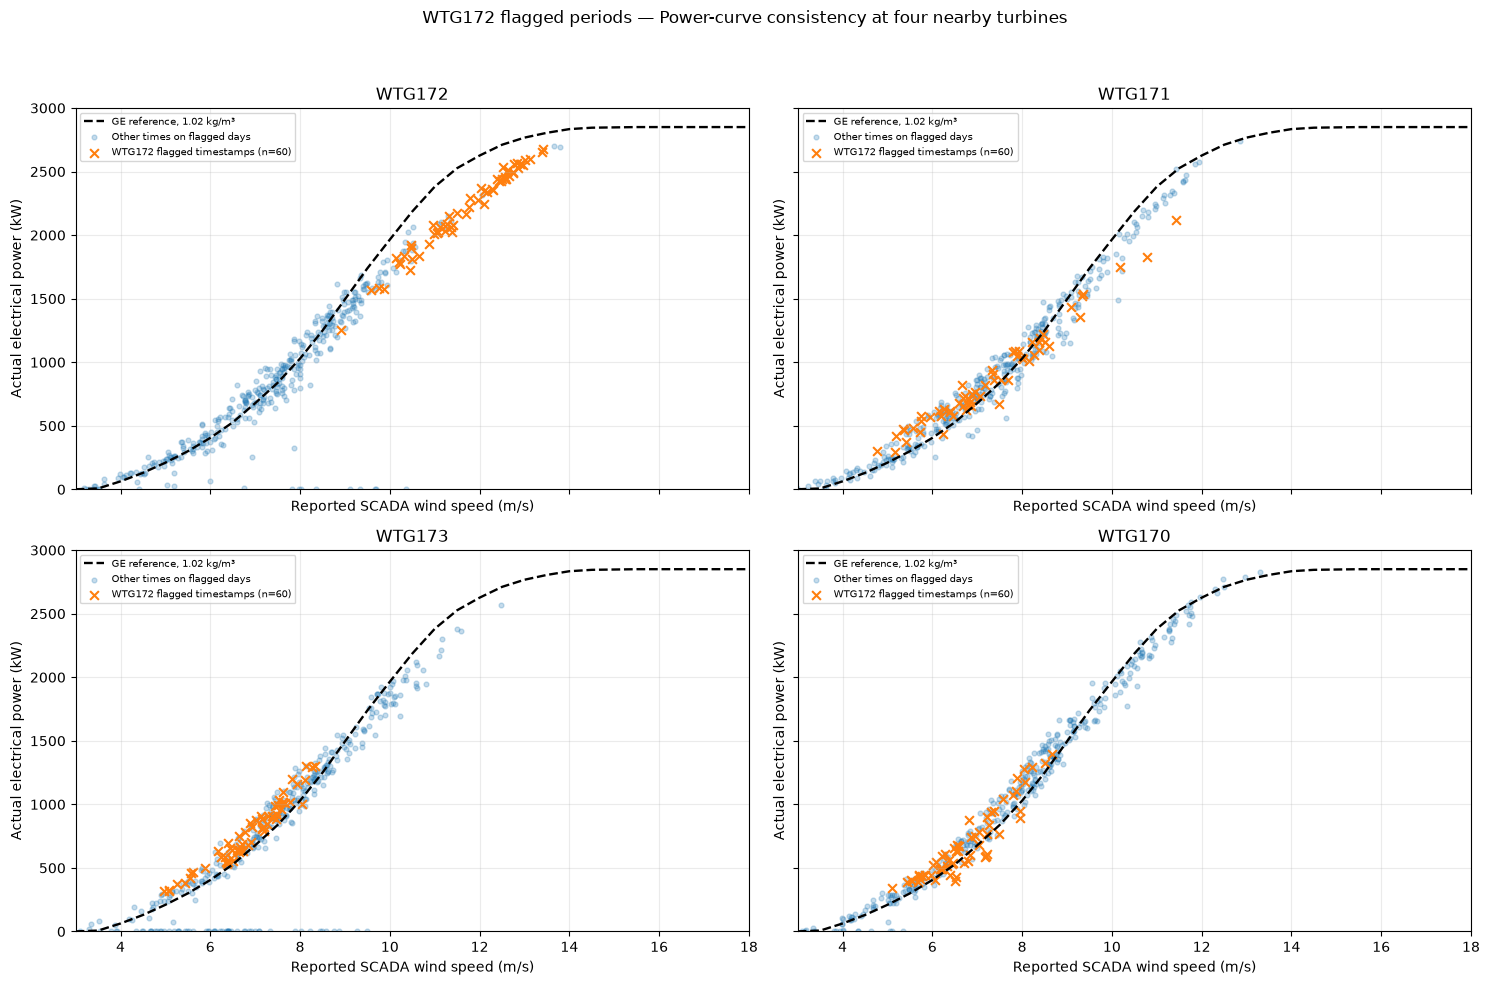

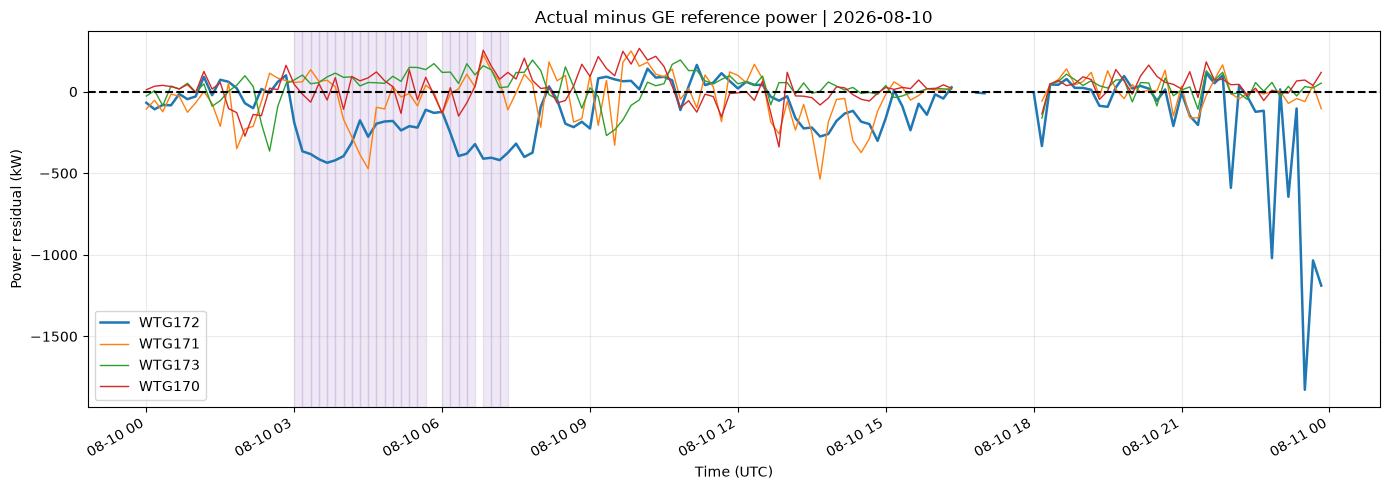

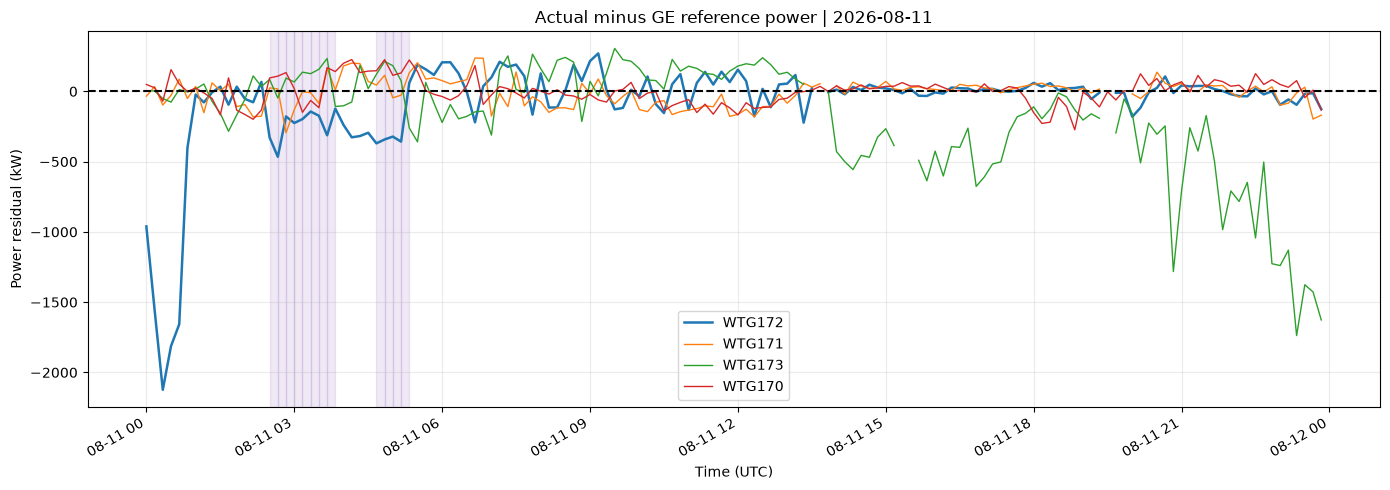

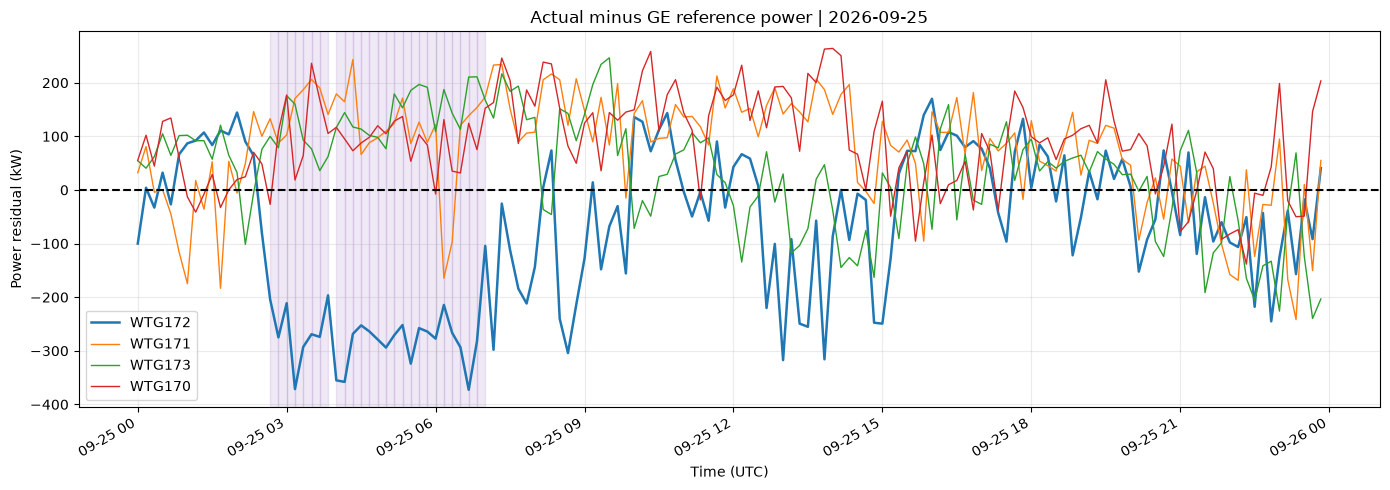


WTG172 CHANNEL AND POWER DIAGNOSTICS COMPLETE

Flagged observations: 60
Complete four-turbine measurements: 60

Reports saved to:
C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\processed\10_WTG172_channel_power_validation

IMPORTANT:
Field agreement and power consistency cannot establish whether SCADA wind speed is power-derived or independent.
We still require SCADA channel definitions, operating-state records, and a validated wind reference for instrument diagnosis.


In [28]:

# ===============================================================
# 10 — WTG172: SCADA Channel and Power-Consistency Investigation
# Uses the original SCADA data and exact 08 screening flags.
# No changes to the wake model or screening decisions.
# ===============================================================

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ===============================================================
# 1. Locate the project and screening results
# ===============================================================

ROOT_10 = Path(PROJECT_ROOT) if "PROJECT_ROOT" in globals() else Path(
    r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
)

SCREEN_ROOT_10 = ROOT_10 / "data/processed/08_scada_screening"

OUT_10 = (
    ROOT_10
    / "data/processed/10_WTG172_channel_power_validation"
)
OUT_10.mkdir(parents=True, exist_ok=True)

# Reuse the same 08 run as the previous investigation.
RUN_10 = None

for key in ["RUN_C", "screening_run", "run"]:
    value = globals().get(key)

    if isinstance(value, (str, Path)) and Path(value).is_dir():
        proposed = Path(value)

        if (
            proposed / "intervals/WTG172_screened_intervals.csv"
        ).exists() and (
            proposed / "08_fixed_peers.csv"
        ).exists():
            RUN_10 = proposed
            break

if RUN_10 is None:
    RUN_10 = next(
        (
            p for p in sorted(
                SCREEN_ROOT_10.glob("run_*"),
                reverse=True
            )
            if (
                p / "intervals/WTG172_screened_intervals.csv"
            ).exists()
            and (p / "08_fixed_peers.csv").exists()
        ),
        None
    )

if RUN_10 is None:
    raise FileNotFoundError(
        "No completed 08 screening run found."
    )

print("Screening run:", RUN_10)


# ===============================================================
# 2. Load exact WTG172 flagged observations
# ===============================================================

flag_source_10 = pd.read_csv(
    RUN_10 / "intervals/WTG172_screened_intervals.csv"
)

flag_source_10["timestamp"] = pd.to_datetime(
    flag_source_10["timestamp"],
    utc=True,
    errors="coerce"
)

if (
    flag_source_10["timestamp"].isna().any()
    or flag_source_10["timestamp"].duplicated().any()
):
    raise ValueError(
        "Invalid or duplicate screening timestamps."
    )


def bool_10(series):
    text = series.astype(str).str.strip().str.lower()

    valid = {
        "true": True,
        "1": True,
        "1.0": True,
        "false": False,
        "0": False,
        "0.0": False
    }

    if not text.isin(valid).all():
        raise ValueError("Unknown screening flag value.")

    return text.map(valid).astype(bool)


flag_source_10["flagged"] = (
    bool_10(flag_source_10["departure_episode"])
    | bool_10(flag_source_10["flat_episode"])
)

if "period" in flag_source_10.columns:
    flag_source_10["flagged"] &= (
        flag_source_10["period"] == "later_evaluation"
    )

flag_times_10 = pd.DatetimeIndex(
    flag_source_10.loc[
        flag_source_10["flagged"],
        "timestamp"
    ]
).unique().sort_values()

if len(flag_times_10) == 0:
    raise ValueError("No flagged WTG172 observations.")

flag_days_10 = flag_times_10.floor("D").unique()

peers_10 = (
    pd.read_csv(RUN_10 / "08_fixed_peers.csv")
    .query("turbine == 'WTG172'")
    .sort_values("rank")["peer"]
    .tolist()
)

if len(peers_10) != 3 or len(set(peers_10)) != 3:
    raise ValueError("Expected three fixed peers.")

sites_10 = ["WTG172"] + peers_10

print("Turbines:", sites_10)
print("Flagged observations:", len(flag_times_10))
print("Distinct flagged days:", len(flag_days_10))


# ===============================================================
# 3. Load original SCADA data, preserving source columns
# ===============================================================

raw_10 = pd.read_parquet(
    ROOT_10 / "data/processed/scada_data.parquet"
).copy()

if "turbine" not in raw_10.columns:
    raw_10 = raw_10.reset_index()

if not any(
    c in raw_10.columns for c in ["utc", "timestamp"]
):
    raw_10 = raw_10.reset_index()


def id_10(value):
    if pd.isna(value):
        return pd.NA

    match = re.fullmatch(
        r"(?:(?:WTG[_\s-]*T?|GE)[_\s-]*)?(\d+)(?:\.0)?",
        str(value).strip().upper()
    )

    if not match:
        raise ValueError(f"Unknown turbine ID: {value!r}")

    return "WTG" + str(int(match.group(1)))


raw_10["turbine"] = raw_10["turbine"].map(id_10)

raw_10 = raw_10[
    raw_10["turbine"].isin(sites_10)
].copy()

time_col_10 = (
    "utc" if "utc" in raw_10.columns
    else "timestamp"
)

raw_10["utc_10"] = pd.to_datetime(
    raw_10[time_col_10],
    errors="coerce",
    utc=True
)

if (
    raw_10["utc_10"].isna().any()
    or raw_10.duplicated(["utc_10", "turbine"]).any()
):
    raise ValueError(
        "Missing or duplicated SCADA timestamps."
    )

wind_source_10 = next(
    (
        c for c in ["wind_speed", "KPI_wind_speed"]
        if c in raw_10.columns
    ),
    None
)

power_source_10 = next(
    (
        c for c in ["KPI_real_power_ac", "real_power_ac"]
        if c in raw_10.columns
    ),
    None
)

if wind_source_10 is None or power_source_10 is None:
    raise KeyError(
        "Compatible SCADA wind or electrical-power field missing."
    )

numeric_fields_10 = [
    "wind_speed",
    "KPI_wind_speed",
    "real_power_ac",
    "KPI_real_power_ac",
    "KPI_theoretical_power",
    "air_density"
]

for field in numeric_fields_10:
    if field in raw_10.columns:
        raw_10[field] = pd.to_numeric(
            raw_10[field],
            errors="coerce"
        )

raw_10["observed_wind_ms"] = raw_10[wind_source_10]
raw_10["observed_power_kw"] = raw_10[power_source_10]

# Check expected kW scale; don't silently convert units.
q99_10 = raw_10["observed_power_kw"].quantile(0.99)

if (
    not np.isfinite(q99_10)
    or not (500 <= q99_10 <= 5000)
):
    raise ValueError(
        f"Power 99th percentile = {q99_10:.2f}. "
        "Verify electrical-power units are kW."
    )

raw_10["flagged"] = raw_10["utc_10"].isin(flag_times_10)

raw_10["on_flag_day"] = (
    raw_10["utc_10"].dt.floor("D").isin(flag_days_10)
)

print("\n--- SCADA FIELD INVENTORY ---")

for col in numeric_fields_10:
    print(
        col,
        "AVAILABLE" if col in raw_10.columns else "NOT AVAILABLE"
    )

print("\nWind-speed field selected:", wind_source_10)
print("Power field selected:", power_source_10)


# ===============================================================
# 4. Compare wind_speed vs KPI_wind_speed
#    and real_power_ac vs KPI_real_power_ac
# ===============================================================

channel_rows_10 = []

for turbine in sites_10:

    sub = raw_10[
        raw_10["turbine"] == turbine
    ]

    comparisons = [
        (
            "Wind speed vs KPI wind speed",
            "wind_speed",
            "KPI_wind_speed",
            0.01
        ),
        (
            "Electrical power vs KPI electrical power",
            "real_power_ac",
            "KPI_real_power_ac",
            1.0
        )
    ]

    for label, first, second, tolerance in comparisons:

        if first not in sub.columns or second not in sub.columns:
            channel_rows_10.append({
                "turbine": turbine,
                "comparison": label,
                "paired_n": 0,
                "pct_nearly_identical": np.nan,
                "median_difference": np.nan,
                "correlation": np.nan
            })
            continue

        valid = sub[[first, second]].dropna()

        difference = valid[second] - valid[first]

        channel_rows_10.append({
            "turbine": turbine,
            "comparison": label,
            "paired_n": len(valid),
            "pct_nearly_identical": (
                100 * np.isclose(
                    valid[first],
                    valid[second],
                    atol=tolerance,
                    rtol=0
                ).mean()
                if len(valid) else np.nan
            ),
            "median_difference": difference.median(),
            "correlation": (
                valid[first].corr(valid[second])
                if len(valid) > 2 else np.nan
            )
        })

channel_report_10 = pd.DataFrame(channel_rows_10)

print("\n--- SCADA RAW-NAME VS KPI-NAME COMPARISONS ---")
display(channel_report_10.round(3))

channel_report_10.to_csv(
    OUT_10 / "10_scada_channel_comparison.csv",
    index=False
)


# ===============================================================
# 5. Load GE manufacturer reference power curve
# ===============================================================

curve_path_10 = (
    ROOT_10 / "data/raw/GE_2_85MW_103mRD_PC.csv"
)

if not curve_path_10.exists():
    raise FileNotFoundError(curve_path_10)

ref_10 = pd.read_csv(curve_path_10)

ref_10.columns = ref_10.columns.str.strip()

for col in ["WINDSPEED", "POWER_KW", "AIR_DENSITY"]:
    ref_10[col] = pd.to_numeric(
        ref_10[col],
        errors="coerce"
    )

# Single reference-density and normal-TI curve
ref_10 = ref_10[
    np.isclose(
        ref_10["AIR_DENSITY"],
        1.02,
        atol=0.001
    )
    & ref_10["TI_CLASS"]
      .astype(str).str.strip().str.lower().eq("normal")
].dropna(
    subset=["WINDSPEED", "POWER_KW"]
)

ref_10 = (
    ref_10.groupby("WINDSPEED", as_index=False)["POWER_KW"]
    .mean()
    .sort_values("WINDSPEED")
)

if len(ref_10) < 2:
    raise ValueError(
        "Reference power curve has insufficient valid points."
    )

# Diagnostic prediction at reported wind speed.
# This does not correct each timestamp for density.
raw_10["GE_expected_kw"] = np.interp(
    raw_10["observed_wind_ms"].to_numpy(dtype=float),
    ref_10["WINDSPEED"].to_numpy(dtype=float),
    ref_10["POWER_KW"].to_numpy(dtype=float),
    left=np.nan,
    right=np.nan
)

raw_10["actual_minus_GE_kw"] = (
    raw_10["observed_power_kw"]
    - raw_10["GE_expected_kw"]
)

raw_10["density_near_reference"] = (
    raw_10["air_density"].between(0.99, 1.05)
    if "air_density" in raw_10.columns
    else False
)


# ===============================================================
# 6. Compare power consistency on the flagged days
# ===============================================================

events_10 = raw_10[
    raw_10["on_flag_day"]
].copy()

events_10["group"] = np.where(
    events_10["flagged"],
    "Flagged",
    "Other times on flagged days"
)

summary_10 = (
    events_10.groupby(["turbine", "group"])
    .agg(
        records=("utc_10", "size"),
        available_wind=("observed_wind_ms", "count"),
        available_power=("observed_power_kw", "count"),
        mean_wind_ms=("observed_wind_ms", "mean"),
        mean_actual_power_kw=("observed_power_kw", "mean"),
        mean_GE_expected_kw=("GE_expected_kw", "mean"),
        mean_actual_minus_GE_kw=(
            "actual_minus_GE_kw", "mean"
        ),
        near_reference_density_n=(
            "density_near_reference", "sum"
        )
    )
    .reset_index()
)

print("\n--- POWER CONSISTENCY BY TURBINE ---")
display(summary_10.round(2))

# Count strictly simultaneous four-turbine coverage
wind_wide_10 = events_10.pivot(
    index="utc_10",
    columns="turbine",
    values="observed_wind_ms"
)

power_wide_10 = events_10.pivot(
    index="utc_10",
    columns="turbine",
    values="observed_power_kw"
)

common_10 = (
    wind_wide_10[sites_10].notna().all(axis=1)
    & power_wide_10[sites_10].notna().all(axis=1)
)

complete_flagged_10 = int(
    common_10.reindex(
        flag_times_10,
        fill_value=False
    ).sum()
)

print(
    "\nComplete four-turbine comparisons:",
    complete_flagged_10,
    "of",
    len(flag_times_10)
)

summary_10.to_csv(
    OUT_10 / "10_power_summary_by_turbine_and_flag.csv",
    index=False
)

events_10.to_csv(
    OUT_10 / "10_event_days_all_four_scada.csv",
    index=False
)


# ===============================================================
# 7. Compare flagged readings with similar unflagged readings
#    Same turbine, same month, same 0.5 m/s wind-speed bin
# ===============================================================

raw_10["month_10"] = (
    raw_10["utc_10"].dt.strftime("%Y-%m")
)

raw_10["speed_bin_10"] = np.floor(
    raw_10["observed_wind_ms"] / 0.5
).astype("Int64")

ref_bins_10 = (
    raw_10[
        (~raw_10["flagged"])
        & raw_10["actual_minus_GE_kw"].notna()
    ]
    .groupby(
        ["turbine", "month_10", "speed_bin_10"],
        observed=True
    )["actual_minus_GE_kw"]
    .agg(
        reference_n="size",
        reference_mean_kw="mean"
    )
    .reset_index()
)

matched_10 = raw_10[
    raw_10["flagged"]
    & raw_10["actual_minus_GE_kw"].notna()
].merge(
    ref_bins_10,
    on=["turbine", "month_10", "speed_bin_10"],
    how="left",
    validate="many_to_one"
)

# Minimum ten nonflagged comparison records
matched_10 = matched_10[
    matched_10["reference_n"] >= 10
].copy()

matched_10["gap_minus_comparable_kw"] = (
    matched_10["actual_minus_GE_kw"]
    - matched_10["reference_mean_kw"]
)

match_report_10 = (
    matched_10.groupby("turbine")
    .agg(
        flagged_intervals_with_comparators=(
            "utc_10", "size"
        ),
        mean_gap_vs_similar_nonflagged_kw=(
            "gap_minus_comparable_kw", "mean"
        )
    )
    .reindex(sites_10)
    .reset_index()
)

print("\n--- SPEED-MATCHED POWER COMPARISON ---")
display(match_report_10.round(2))

match_report_10.to_csv(
    OUT_10 / "10_speed_matched_power_comparison.csv",
    index=False
)

matched_10.to_csv(
    OUT_10 / "10_flagged_power_speed_matched_details.csv",
    index=False
)


# ===============================================================
# 8. Search for potential turbine status / curtailment fields
# ===============================================================

status_columns_10 = [
    c for c in raw_10.columns
    if re.search(
        r"status|state|curtail|derat|limit|setpoint|"
        r"alarm|fault|mode|dispatch|availab|operation",
        c,
        flags=re.IGNORECASE
    )
]

print("\n--- POSSIBLE TURBINE OPERATING FIELDS ---")
print(
    status_columns_10
    if status_columns_10
    else "No matching field names found."
)

if status_columns_10:

    status_sample_10 = raw_10[
        raw_10["utc_10"].isin(flag_times_10)
    ][
        ["utc_10", "turbine"] + status_columns_10
    ].copy()

    status_sample_10.to_csv(
        OUT_10 / "10_possible_status_fields_flagged.csv",
        index=False
    )

    status_rows_10 = []

    for col in status_columns_10:

        for turbine in sites_10:

            values = status_sample_10.loc[
                status_sample_10["turbine"] == turbine,
                col
            ]

            status_rows_10.append({
                "turbine": turbine,
                "field": col,
                "nonmissing_flagged": int(
                    values.notna().sum()
                ),
                "distinct_values": int(
                    values.nunique(dropna=True)
                ),
                "examples": ", ".join(
                    map(
                        str,
                        values.dropna().unique()[:4]
                    )
                )
            })

    display(pd.DataFrame(status_rows_10))

print(
    "Status field meanings require sponsor confirmation."
)


# ===============================================================
# 9. Plot power curves for all four turbines
# ===============================================================

fig, axs = plt.subplots(
    2, 2,
    figsize=(15, 10),
    sharex=True,
    sharey=True
)

for ax, turbine in zip(axs.flat, sites_10):

    sub = events_10[
        events_10["turbine"] == turbine
    ]

    normal = sub[
        ~sub["flagged"]
    ]

    marked = sub[
        sub["flagged"]
    ]

    ax.plot(
        ref_10["WINDSPEED"],
        ref_10["POWER_KW"],
        color="black",
        linestyle="--",
        linewidth=1.7,
        label="GE reference, 1.02 kg/m³"
    )

    ax.scatter(
        normal["observed_wind_ms"],
        normal["observed_power_kw"],
        s=12,
        alpha=0.25,
        label="Other times on flagged days"
    )

    ax.scatter(
        marked["observed_wind_ms"],
        marked["observed_power_kw"],
        s=40,
        marker="x",
        label=f"WTG172 flagged timestamps (n={len(marked)})"
    )

    ax.set_title(turbine)
    ax.set_xlim(3, 18)
    ax.set_ylim(0, 3000)
    ax.set_xlabel("Reported SCADA wind speed (m/s)")
    ax.set_ylabel("Actual electrical power (kW)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7)

fig.suptitle(
    "WTG172 flagged periods — Power-curve consistency "
    "at four nearby turbines"
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

fig.savefig(
    OUT_10 / "10_four_turbine_power_curves_flagged.png",
    dpi=190,
    bbox_inches="tight"
)

plt.show()


# ===============================================================
# 10. Plot actual minus expected power for each flagged day
# ===============================================================

for day in flag_days_10:

    selected = events_10[
        events_10["utc_10"].dt.floor("D") == day
    ]

    timeline = pd.date_range(
        day,
        periods=144,
        freq="10min",
        tz="UTC"
    )

    fig, ax = plt.subplots(
        figsize=(14, 5)
    )

    for turbine in sites_10:

        one = (
            selected[
                selected["turbine"] == turbine
            ]
            .set_index("utc_10")
            .reindex(timeline)
        )

        ax.plot(
            timeline,
            one["actual_minus_GE_kw"],
            label=turbine,
            linewidth=1.8 if turbine == "WTG172" else 1
        )

    day_flags = flag_times_10[
        (flag_times_10 >= day)
        & (
            flag_times_10
            < day + pd.Timedelta(days=1)
        )
    ]

    for stamp in day_flags:
        ax.axvspan(
            stamp,
            stamp + pd.Timedelta(minutes=10),
            color="tab:purple",
            alpha=0.15
        )

    ax.axhline(
        0,
        color="black",
        linestyle="--"
    )

    ax.set_title(
        f"Actual minus GE reference power | {day:%Y-%m-%d}"
    )

    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel("Power residual (kW)")
    ax.legend()
    ax.grid(alpha=0.25)

    fig.autofmt_xdate()
    fig.tight_layout()

    fig.savefig(
        OUT_10 / f"10_power_residual_{day:%Y-%m-%d}.png",
        dpi=190,
        bbox_inches="tight"
    )

    plt.show()


# ===============================================================
# 11. Final summary
# ===============================================================

print("\n" + "=" * 60)
print("WTG172 CHANNEL AND POWER DIAGNOSTICS COMPLETE")
print("=" * 60)

print("\nFlagged observations:", len(flag_times_10))

print(
    "Complete four-turbine measurements:",
    complete_flagged_10
)

print("\nReports saved to:")
print(OUT_10)

print("\nIMPORTANT:")
print(
    "Field agreement and power consistency cannot establish "
    "whether SCADA wind speed is power-derived or independent."
)
print(
    "We still require SCADA channel definitions, operating-state "
    "records, and a validated wind reference for instrument diagnosis."
)
